# ML-Enhanced Statistical Arbitrage on NSE Stocks

**BITS Pilani · EEE G513 Machine Learning · Project notebook (simplified version)**

**Pairs trading:** find two stocks that usually move together. When the gap between them becomes
unusually wide, buy the cheap one and sell the expensive one, and profit if the gap closes.
This notebook builds that strategy on ~225 NSE futures (F&O) stocks with daily prices from 2014
to 2026. It then replaces four hand-made steps with machine learning:

| Classical step | ML replacement | Course topic |
|---|---|---|
| Test every possible pair | PCA + clustering (k-means, GMM, OPTICS) | Unsupervised learning |
| Fixed hedge ratio from one regression | Kalman filter (the hedge ratio changes daily) | Bayesian linear regression |
| Take every trading signal | Meta-labeling classifier that filters and sizes trades | Supervised learning |
| OU formula for how fast the gap closes | TCN neural network forecaster | Deep learning |

Every comparison is **out of sample** (on data the models never saw) and **after Indian trading
costs**.

## Contents
1. Setup
2. Data and trading costs
3. Finding pairs
4. The spread and the trading rule
5. The backtest engine
6. Experiments: classical baseline, pair selection, hedge ratios
7. Meta-labeling
8. Deep learning
9. Final evaluation
10. Conclusions

**How to run:** keep this notebook next to the `data/` folder, use a Python environment with the
packages in `requirements.txt` as the kernel, then *Run All*. Everything this notebook makes goes into `simple_outputs/`. The first
run computes everything (about 20 minutes); later runs reuse the saved results and take a few
minutes. Prices are read from `data/raw/`, or downloaded if that folder is empty.

---
# 1. Setup
## 1.1 Libraries

In [1]:
import copy
import os
import pickle
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display

from scipy.stats import norm, skew, kurtosis
from statsmodels.tsa.stattools import coint, adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.stats.multitest import multipletests

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, OPTICS
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import silhouette_score, roc_auc_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from lightgbm import LGBMClassifier

# import torch AFTER scikit-learn and LightGBM: on macOS the other order loads two copies of
# the OpenMP library and k-means crashes the kernel
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")    # statsmodels warns when two price series are almost identical
torch.set_num_threads(4)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 1.2 Settings
Every number used in the project is in this one dictionary. To try a different setting, change it
here (or copy the dictionary and change one value, as the sensitivity analysis in Part 9 does).

In [2]:
config = {
    "seed": 42,

    # data
    "start_date": "2014-01-01",
    "end_date": "2026-11-14",
    "max_missing_share": 0.05,      # leave a stock out of a window if more than 5% of its days are missing
    "max_forward_fill_days": 2,     # fill at most 2 missing days in a row
    "jump_flag_threshold": 0.25,    # a one-day move above 25% is treated as bad data

    # walk-forward windows (in trading days)
    "formation_days": 252,          # learn on 1 year ...
    "trading_days": 126,            # ... trade the next 6 months, then move forward 6 months

    # pair selection
    "fdr_alpha": 0.05,              # Benjamini-Hochberg false discovery rate
    "max_pvalue": 0.05,             # a pair must pass the cointegration test at 5%
    "min_half_life": 5,
    "max_half_life": 60,
    "min_crossings_per_year": 12,
    "max_pairs": 20,                # pairs traded per window
    "max_pairs_per_stock": 3,
    "pca_components": 10,
    "k_choices": [4, 6, 8, 10, 12], # numbers of clusters to try
    "optics_min_samples": 3,

    # trading rule
    "entry_z": 2.0,
    "exit_z": 0.0,
    "stop_z": 4.0,
    "time_stop_half_lives": 2.0,
    "execution_delay": 1,           # signal at the close of day t, trade at the close of day t+1
    "capital_per_pair": 2000000,    # rupees

    # hedge ratio
    "rolling_window": 60,
    "kalman_delta_choices": [0.00001, 0.0001, 0.001],
    "kalman_r_multipliers": [0.1, 0.5, 1.0],
    "kalman_warmup_days": 30,

    # Zerodha futures charges + slippage
    "stt_sell": 0.0005,
    "brokerage_rate": 0.0003,
    "brokerage_cap": 20.0,
    "exchange_rate": 0.0000183,
    "stamp_buy": 0.00002,
    "gst_rate": 0.18,
    "sebi_rate": 0.000001,
    "slippage_rate": 0.0004,
    "cost_multiplier": 1.0,         # 2.0 = the "double costs" check

    # meta-labeling
    "label_type": "pnl",            # "pnl" = trade made money after costs, "barrier" = spread reached its mean
    "min_train_windows": 6,
    "cv_folds": 4,
    "embargo_days": 10,
    "keep_share_choices": [1.0, 0.8, 0.6, 0.4],
    "size_cap": 1.5,

    # deep learning (TCN)
    "lookback": 60,
    "horizon": 5,
    "channels": 16,
    "layers": 4,
    "dropout": 0.1,
    "epochs": 30,
    "patience": 5,
    "batch_size": 128,
    "learning_rate": 0.001,
    "pair_cost_bps": 28,

    # evaluation
    "bootstrap_samples": 1000,
    "bootstrap_block_days": 20,

    # sanity test switch (see Part 6)
    "shuffle_test": False,
}

np.random.seed(config["seed"])
torch.manual_seed(config["seed"])

## 1.3 Folders and small helpers
Results are saved with `pickle` so that a second run does not have to recompute them. A saved
backtest is only reused if it was made with exactly the same settings.

`TRIALS` records the Sharpe ratio of every strategy variant we try. Part 9 needs this list to
check whether the best result could just be luck.

In [3]:
OUTPUT_FOLDER = "simple_outputs"
CACHE_FOLDER = os.path.join(OUTPUT_FOLDER, "cache")
TABLE_FOLDER = os.path.join(OUTPUT_FOLDER, "tables")
FIGURE_FOLDER = os.path.join(OUTPUT_FOLDER, "figures")
for folder in [CACHE_FOLDER, TABLE_FOLDER, FIGURE_FOLDER]:
    os.makedirs(folder, exist_ok=True)

# downloaded prices: use the project's existing download if there is one
RAW_FOLDER = os.path.join("data", "raw")
if not os.path.exists(os.path.join(RAW_FOLDER, "close.parquet")):
    RAW_FOLDER = os.path.join(OUTPUT_FOLDER, "raw")


def save_pickle(thing, name):
    with open(os.path.join(CACHE_FOLDER, name + ".pkl"), "wb") as file:
        pickle.dump(thing, file)


def load_pickle(name):
    path = os.path.join(CACHE_FOLDER, name + ".pkl")
    if not os.path.exists(path):
        return None
    with open(path, "rb") as file:
        return pickle.load(file)


def save_table(table, name):
    """Save a table as CSV and show it."""
    table.to_csv(os.path.join(TABLE_FOLDER, name + ".csv"), index=False)
    display(table)


def save_figure(figure, file_name):
    """Save a figure as PNG and show it."""
    figure.tight_layout()
    figure.savefig(os.path.join(FIGURE_FOLDER, file_name), dpi=130)
    plt.show()


TRIALS = {}


def log_trial(name, returns):
    """Remember the daily Sharpe ratio of one strategy variant."""
    std = returns.std()
    TRIALS[name] = float(returns.mean() / std) if std > 0 else 0.0

---
# 2. Data and trading costs

## 2.1 The stock universe
About 225 NSE stocks that trade in the futures segment, grouped into 15 sectors. The sectors are
used by the "same sector" pair selector and by the error analysis.

> **Limitation (survivorship bias).** This is today's list. Stocks that left the futures segment in
> the past are missing.

In [4]:
SECTORS = {
    "Banks": [
        "HDFCBANK", "ICICIBANK", "SBIN", "KOTAKBANK", "AXISBANK", "INDUSINDBK",
        "BANKBARODA", "PNB", "CANBK", "FEDERALBNK", "IDFCFIRSTB", "BANDHANBNK",
        "AUBANK", "RBLBANK", "UNIONBANK", "INDIANB", "YESBANK", "BANKINDIA",
    ],
    "Financials": [
        "BAJFINANCE", "BAJAJFINSV", "HDFCLIFE", "SBILIFE", "ICICIPRULI", "ICICIGI",
        "CHOLAFIN", "SHRIRAMFIN", "MUTHOOTFIN", "MANAPPURAM", "LICHSGFIN", "PFC",
        "RECLTD", "M&MFIN", "LTF", "HDFCAMC", "SBICARD", "ABCAPITAL", "MFSL",
        "IEX", "MCX", "BSE", "CDSL", "ANGELONE", "PNBHOUSING", "LICI", "JIOFIN",
        "POLICYBZR", "PAYTM", "HUDCO", "IRFC",
    ],
    "IT": [
        "TCS", "INFY", "HCLTECH", "WIPRO", "TECHM", "LTIM", "MPHASIS", "COFORGE",
        "PERSISTENT", "OFSS", "LTTS", "KPITTECH", "TATAELXSI", "BSOFT", "CYIENT",
        "NAUKRI",
    ],
    "Auto": [
        "MARUTI", "M&M", "BAJAJ-AUTO", "HEROMOTOCO", "EICHERMOT", "TVSMOTOR",
        "ASHOKLEY", "BHARATFORG", "MOTHERSON", "BOSCHLTD", "MRF", "APOLLOTYRE",
        "BALKRISIND", "EXIDEIND", "ESCORTS", "TIINDIA", "SONACOMS", "UNOMINDA",
    ],
    "Pharma": [
        "SUNPHARMA", "DRREDDY", "CIPLA", "DIVISLAB", "LUPIN", "AUROPHARMA",
        "BIOCON", "TORNTPHARM", "ALKEM", "ZYDUSLIFE", "GLENMARK", "LAURUSLABS",
        "IPCALAB", "GRANULES", "ABBOTINDIA", "APOLLOHOSP", "MAXHEALTH", "FORTIS",
        "SYNGENE", "LALPATHLAB", "METROPOLIS", "MANKIND",
    ],
    "FMCG": [
        "HINDUNILVR", "ITC", "NESTLEIND", "BRITANNIA", "DABUR", "MARICO",
        "GODREJCP", "COLPAL", "TATACONSUM", "UBL", "UNITDSPR", "VBL", "PATANJALI",
    ],
    "Consumer": [
        "TITAN", "ASIANPAINT", "BERGEPAINT", "PIDILITIND", "HAVELLS", "VOLTAS",
        "CROMPTON", "DIXON", "BATAINDIA", "PAGEIND", "TRENT", "DMART", "JUBLFOOD",
        "INDHOTEL", "IRCTC", "ABFRL", "KALYANKJIL", "POLYCAB", "KEI", "BLUESTARCO",
        "NYKAA", "PVRINOX", "SUNTV", "ZEEL", "INDIGO",
    ],
    "Metals": [
        "TATASTEEL", "JSWSTEEL", "HINDALCO", "VEDL", "JINDALSTEL", "SAIL", "NMDC",
        "NATIONALUM", "HINDZINC", "COALINDIA", "APLAPOLLO", "HINDCOPPER", "JSL",
    ],
    "Energy": [
        "RELIANCE", "ONGC", "IOC", "BPCL", "HINDPETRO", "GAIL", "PETRONET", "IGL",
        "MGL", "OIL", "GUJGASLTD", "ATGL",
    ],
    "Power": [
        "NTPC", "POWERGRID", "TATAPOWER", "ADANIGREEN", "NHPC", "SJVN",
        "TORNTPOWER", "JSWENERGY", "ADANIENSOL", "CESC",
    ],
    "Industrials": [
        "LT", "SIEMENS", "ABB", "BHEL", "BEL", "HAL", "CUMMINSIND", "CGPOWER",
        "ADANIENT", "ADANIPORTS", "CONCOR", "GMRAIRPORT", "IRB", "NBCC", "RVNL",
        "BDL", "MAZDOCK", "SOLARINDS", "SUPREMEIND", "ASTRAL",
    ],
    "Cement": [
        "ULTRACEMCO", "SHREECEM", "AMBUJACEM", "ACC", "GRASIM", "DALBHARAT",
        "RAMCOCEM", "JKCEMENT",
    ],
    "Chemicals": [
        "UPL", "PIIND", "SRF", "AARTIIND", "DEEPAKNTR", "TATACHEM", "COROMANDEL",
        "CHAMBLFERT", "NAVINFLUOR", "ATUL", "GNFC",
    ],
    "Telecom": ["BHARTIARTL", "IDEA", "INDUSTOWER", "TATACOMM"],
    "Realty": ["DLF", "GODREJPROP", "OBEROIRLTY", "PRESTIGE", "LODHA", "PHOENIXLTD"],
}

NIFTY_TICKER = "^NSEI"
VIX_TICKER = "^INDIAVIX"

SECTOR_OF = {}           # stock -> sector
for sector, tickers in SECTORS.items():
    for ticker in tickers:
        SECTOR_OF[ticker] = sector
ALL_TICKERS = sorted(SECTOR_OF)
print(f"{len(ALL_TICKERS)} stocks in {len(SECTORS)} sectors")

227 stocks in 15 sectors


## 2.2 Download
Daily closing prices adjusted for splits and bonuses, plus traded volume, from Yahoo Finance. NIFTY
50 and India VIX describe the market. The download only happens if no saved copy exists.

In [5]:
def download_prices(tickers, start_date, end_date):
    """Adjusted close and volume from Yahoo Finance, 40 tickers per request."""
    closes = []
    volumes = []
    for i in range(0, len(tickers), 40):
        batch = tickers[i:i + 40]
        print(f"  downloading {batch[0]} to {batch[-1]}")
        raw = yf.download(batch, start=start_date, end=end_date, auto_adjust=True,
                          progress=False, group_by="column", threads=True)
        closes.append(raw["Close"])
        volumes.append(raw["Volume"])
    return pd.concat(closes, axis=1), pd.concat(volumes, axis=1)

In [6]:
if not os.path.exists(os.path.join(RAW_FOLDER, "close.parquet")):
    os.makedirs(RAW_FOLDER, exist_ok=True)
    yahoo_names = [ticker + ".NS" for ticker in ALL_TICKERS]
    close, volume = download_prices(yahoo_names, config["start_date"], config["end_date"])

    # "RELIANCE.NS" -> "RELIANCE", and drop tickers with no data at all
    names = [name.replace(".NS", "") for name in close.columns]
    close.columns = names
    volume.columns = names
    has_data = [name for name in names if close[name].notna().sum() > 0]
    close = close[has_data].sort_index().sort_index(axis=1)
    volume = volume[has_data].sort_index().sort_index(axis=1)

    index_close, _ = download_prices([NIFTY_TICKER, VIX_TICKER], config["start_date"], config["end_date"])
    market = pd.DataFrame(index=index_close.index)
    market["NIFTY"] = index_close[NIFTY_TICKER]
    market["VIX"] = index_close[VIX_TICKER]
    market = market.sort_index()

    close.to_parquet(os.path.join(RAW_FOLDER, "close.parquet"))
    volume.to_parquet(os.path.join(RAW_FOLDER, "volume.parquet"))
    market.to_parquet(os.path.join(RAW_FOLDER, "market.parquet"))

close = pd.read_parquet(os.path.join(RAW_FOLDER, "close.parquet"))
volume = pd.read_parquet(os.path.join(RAW_FOLDER, "volume.parquet"))
market = pd.read_parquet(os.path.join(RAW_FOLDER, "market.parquet"))
print(f"Loaded {close.shape[1]} stocks from {RAW_FOLDER}")

Loaded 225 stocks from data/raw


## 2.3 Cleaning
- Keep only real trading days (days on which at least half of the stocks traded).
- Fill at most 2 missing days in a row with the last price.
- A one-day move above 25% is treated as a data error: that stock is left out of the window in
  which it happens (Part 5).
- Monthly futures expiry is the last Thursday of the month. Holding a trade through expiry costs a
  "roll", as the futures position has to be moved to the next month.

In [7]:
def clean_prices(close, volume, market, config):
    """Return cleaned (prices, volume, market) on one common calendar of trading days."""
    close = close.where(close > 0)                     # a price of 0 or below is an error

    stocks_per_day = close.notna().sum(axis=1)
    trading_days = stocks_per_day[stocks_per_day >= 0.5 * stocks_per_day.max()].index
    close = close.loc[trading_days]
    volume = volume.reindex(trading_days)

    prices = close.ffill(limit=config["max_forward_fill_days"])
    volume = volume.fillna(0)
    market = market.reindex(trading_days).ffill().bfill()
    return prices, volume, market


def find_expiry_days(dates):
    """True on monthly futures expiry days (the last trading day on or before the last Thursday)."""
    is_expiry = np.zeros(len(dates), dtype=bool)
    months_done = set()
    for position in range(len(dates) - 1, -1, -1):          # walk backwards through the dates
        date = dates[position]
        month = (date.year, date.month)
        if month in months_done:
            continue
        last_day = date + pd.offsets.MonthEnd(0)
        last_thursday = last_day - pd.Timedelta(days=(last_day.weekday() - 3) % 7)
        if date <= last_thursday:
            is_expiry[position] = True
            months_done.add(month)
    return is_expiry

In [8]:
prices, volume, market = clean_prices(close, volume, market, config)

data = {
    "prices": prices,
    "traded_value": prices * volume,      # rupees traded per day
    "market": market,
    "expiry": find_expiry_days(prices.index),
}
nifty_returns = market["NIFTY"].pct_change().fillna(0.0)

returns = prices.pct_change(fill_method=None)
n_jumps = int((returns.abs() > config["jump_flag_threshold"]).sum().sum())
print(f"Clean prices: {prices.shape[0]} days x {prices.shape[1]} stocks, "
      f"{prices.index[0].date()} to {prices.index[-1].date()}")
print(f"Missing prices: {prices.isna().mean().mean() * 100:.2f}%")
print(f"One-day moves above 25%: {n_jumps}")

Clean prices: 3174 days x 225 stocks, 2014-01-01 to 2026-11-13
Missing prices: 8.62%
One-day moves above 25%: 59


## 2.4 Trading costs
Zerodha's charges for stock futures, plus slippage (the price moving against us when we trade):

| Charge | Rate |
|---|---|
| STT (sell side only) | 0.05% |
| Brokerage | 0.03% or ₹20, whichever is lower |
| NSE transaction charge | 0.00183% |
| Stamp duty (buy side only) | 0.002% |
| SEBI fee | ₹10 per crore |
| GST | 18% of brokerage + exchange + SEBI |
| Slippage | 0.04% |

A pair trade is four orders: two to open and two to close.

In [9]:
def order_cost(notional, side, config):
    """Cost in rupees of one buy or one sell of `notional` rupees."""
    brokerage = min(config["brokerage_rate"] * notional, config["brokerage_cap"])
    exchange = config["exchange_rate"] * notional
    sebi = config["sebi_rate"] * notional
    gst = config["gst_rate"] * (brokerage + exchange + sebi)
    slippage = config["slippage_rate"] * notional
    if side == "sell":
        tax = config["stt_sell"] * notional
    else:
        tax = config["stamp_buy"] * notional
    total = brokerage + exchange + sebi + gst + slippage + tax
    return total * config["cost_multiplier"]


def round_trip_cost(notional, config):
    """One buy plus one sell. Rolling a futures leg at expiry costs the same."""
    return order_cost(notional, "buy", config) + order_cost(notional, "sell", config)


one_leg = round_trip_cost(1000000.0, config)
print(f"Buy + sell of Rs 10 lakh: Rs {one_leg:.1f} = {one_leg / 1000000 * 10000:.2f} bps")
print(f"A pair trade (two legs): {2 * one_leg / 1000000 * 10000:.1f} bps of one leg's value")

Buy + sell of Rs 10 lakh: Rs 1412.7 = 14.13 bps
A pair trade (two legs): 28.3 bps of one leg's value


---
# 3. Finding pairs

Every pair is chosen using the **formation window only** (the year before trading starts).

## 3.1 Describing a spread: the Ornstein–Uhlenbeck (OU) model
The spread between two stocks is modelled as a mean-reverting process. In daily steps this is an
AR(1) regression $s_{t+1} = a + b\,s_t + \varepsilon_t$, which gives:

| Quantity | Formula | Meaning |
|---|---|---|
| Speed of reversion | $\theta = -\ln b$ | how strongly the spread is pulled back |
| Long-run mean | $\mu = a/(1-b)$ | where it is pulled to |
| Equilibrium spread | $\sigma_{eq} = \sigma_\varepsilon/\sqrt{1-b^2}$ | its typical distance from the mean |
| Half-life | $\ln 2/\theta$ | days needed to close half of the gap |

The Hurst exponent is another check: below 0.5 means the spread mean-reverts.

In [10]:
def fit_ou(spread):
    """Fit s[t+1] = a + b * s[t] and convert it to OU parameters."""
    x = spread[:-1]
    y = spread[1:]
    b, a = np.polyfit(x, y, 1)
    sigma_noise = (y - (a + b * x)).std()

    result = {"a": a, "b": b, "theta": np.nan, "mu": np.nan, "sigma_eq": np.nan, "half_life": np.nan}
    if 0 < b < 1:                            # only a mean-reverting spread has these
        theta = -np.log(b)
        result["theta"] = theta
        result["mu"] = a / (1 - b)
        result["sigma_eq"] = sigma_noise / np.sqrt(1 - b * b)
        result["half_life"] = np.log(2) / theta
    return result


def count_mean_crossings(spread, mean):
    """How many times the spread crosses its mean."""
    above = spread > mean
    return int((above[1:] != above[:-1]).sum())       # days on which the side changes


def hurst_exponent(series, max_lag=20):
    """Slope of log(std of lag-differences) against log(lag): below 0.5 = mean-reverting."""
    lags = []
    stds = []
    for lag in range(2, max_lag + 1):
        std = (series[lag:] - series[:-lag]).std()
        if std > 0:
            lags.append(lag)
            stds.append(std)
    if len(lags) < 3:
        return np.nan
    slope, _ = np.polyfit(np.log(lags), np.log(stds), 1)
    return slope

## 3.2 Cointegration test and false-discovery control
**Engle–Granger test:** regress $\log A$ on $\log B$ and test whether what is left over (the spread)
is stationary. A small p-value means the spread keeps coming back to its average.

**Testing many pairs:** about 20,000 pairs are tested per window, so about 1,000 would pass at
$p < 0.05$ by pure luck. The **Benjamini–Hochberg** correction sorts the p-values and accepts the
$k$ smallest, where $k$ is the largest rank with $p_{(k)} \le \frac{k}{m}\alpha$. It controls the
share of false pairs among the accepted ones.

**Filters:** half-life of 5–60 days, at least 12 mean crossings a year, positive hedge ratio,
cointegrated in both directions (A on B and B on A), at most 3 pairs per stock, best 20 pairs.
Pairs are ranked by their corrected p-value. Johansen's test is recorded as a second check.

P-values are saved in `PVALUES`, so a pair is never tested twice in the same window.

In [11]:
def engle_granger_pvalue(log_a, log_b):
    """p-value of the Engle-Granger test (small = cointegrated). Lag fixed at 1 for speed."""
    try:
        _, pvalue, _ = coint(log_a, log_b, trend="c", maxlag=1, autolag=None)
    except Exception:
        return 1.0
    if np.isnan(pvalue):
        return 1.0
    return float(pvalue)


def johansen_check(log_a, log_b):
    """True if Johansen's trace test also finds cointegration at 95%."""
    try:
        result = coint_johansen(np.column_stack([log_a, log_b]), det_order=0, k_ar_diff=1)
        return bool(result.lr1[0] > result.cvt[0, 1])
    except Exception:
        return False


def pair_statistics(log_a, log_b):
    """Hedge ratio and spread statistics of one pair on the formation window."""
    beta, _ = np.polyfit(log_b, log_a, 1)
    spread = log_a - beta * log_b
    ou = fit_ou(spread)
    return {
        "beta": beta,
        "half_life": ou["half_life"],
        "sigma_eq": ou["sigma_eq"],
        "theta": ou["theta"],
        "ar_b": ou["b"],
        "crossings": count_mean_crossings(spread, spread.mean()),
        "hurst": hurst_exponent(spread),
        "correlation": np.corrcoef(np.diff(log_a), np.diff(log_b))[0, 1],
        "spread_change_std": np.diff(spread).std(),
    }


def passes_filters(stats, n_days, config):
    """Half-life, mean-crossing and positive-beta filters."""
    if stats["beta"] <= 0 or np.isnan(stats["half_life"]):
        return False
    if stats["half_life"] < config["min_half_life"] or stats["half_life"] > config["max_half_life"]:
        return False
    if stats["crossings"] < config["min_crossings_per_year"] * n_days / 252.0:
        return False
    return True


PVALUES = load_pickle("pvalues")          # {(window start, window end): {(a, b): p-value}}
if PVALUES is None:
    PVALUES = {}

In [12]:
def select_cointegrated(candidates, log_formation, config, cache):
    """Pick the best cointegrated pairs among the candidate pairs. Returns (pairs, info)."""
    for a, b in candidates:
        if (a, b) not in cache:
            cache[(a, b)] = engle_granger_pvalue(log_formation[a].values, log_formation[b].values)
    pvalues = np.array([cache[pair] for pair in candidates])

    if len(pvalues) > 0:
        passes_fdr, adjusted, _, _ = multipletests(pvalues, alpha=config["fdr_alpha"], method="fdr_bh")
    else:
        passes_fdr = np.array([], dtype=bool)
        adjusted = np.array([])
    info = {
        "n_tests": len(candidates),
        "n_raw_pass": int((pvalues < config["max_pvalue"]).sum()),
        "n_fdr_pass": int(passes_fdr.sum()),
    }

    order = np.lexsort((pvalues, adjusted))       # smallest corrected p-value first
    pairs = []
    uses = {}                                     # how many selected pairs each stock is in
    for index in order:
        if len(pairs) >= config["max_pairs"] or pvalues[index] >= config["max_pvalue"]:
            break
        a, b = candidates[index]
        if uses.get(a, 0) >= config["max_pairs_per_stock"] or uses.get(b, 0) >= config["max_pairs_per_stock"]:
            continue
        log_a = log_formation[a].values
        log_b = log_formation[b].values
        stats = pair_statistics(log_a, log_b)
        if not passes_filters(stats, len(log_formation), config):
            continue
        if engle_granger_pvalue(log_b, log_a) >= config["max_pvalue"]:
            continue                              # must also be cointegrated with the legs swapped

        pair = {"a": a, "b": b, "pvalue": float(pvalues[index]),
                "pvalue_adjusted": float(adjusted[index]),
                "johansen_pass": johansen_check(log_a, log_b)}
        pair.update(stats)
        pairs.append(pair)
        uses[a] = uses.get(a, 0) + 1
        uses[b] = uses.get(b, 0) + 1
    return pairs, info

## 3.3 Two simple comparison selectors
- **Distance method (Gatev et al., 2006):** scale both prices to start at 1 and pick the pairs whose
  lines stay closest (smallest sum of squared differences). No statistical test.
- **Random pairs:** random pairs that pass the same filters. This is the "placebo": if a selector
  cannot beat random pairs, it adds nothing.

In [13]:
def all_pairs(tickers):
    """Every pair (a, b) with a before b in alphabetical order."""
    return list(combinations(sorted(tickers), 2))


def make_pair(a, b, log_formation, stats):
    """A pair dictionary for the selectors that do not use the cointegration ranking."""
    pair = {"a": a, "b": b,
            "pvalue": engle_granger_pvalue(log_formation[a].values, log_formation[b].values),
            "pvalue_adjusted": np.nan, "johansen_pass": False}
    pair.update(stats)
    return pair


def select_by_distance(log_formation, config):
    """The closest pairs by the sum of squared differences of normalised prices."""
    tickers = list(log_formation.columns)
    normalised = np.exp(log_formation.values - log_formation.values[0])    # every price starts at 1
    distances = []
    for i in range(len(tickers)):
        difference = normalised[:, i + 1:] - normalised[:, [i]]
        ssd = (difference ** 2).sum(axis=0)
        for k, value in enumerate(ssd):
            distances.append((value, i, i + 1 + k))
    distances.sort()

    pairs = []
    uses = {}
    for _, i, j in distances:
        if len(pairs) >= config["max_pairs"]:
            break
        a, b = tickers[i], tickers[j]
        if uses.get(a, 0) >= config["max_pairs_per_stock"] or uses.get(b, 0) >= config["max_pairs_per_stock"]:
            continue
        stats = pair_statistics(log_formation[a].values, log_formation[b].values)
        if stats["beta"] <= 0:
            continue
        pairs.append(make_pair(a, b, log_formation, stats))
        uses[a] = uses.get(a, 0) + 1
        uses[b] = uses.get(b, 0) + 1
    return pairs, {"n_tests": 0, "n_raw_pass": 0, "n_fdr_pass": 0}


def select_random(log_formation, config, rng):
    """Random pairs that pass the half-life, crossing and beta filters (the null baseline)."""
    candidates = all_pairs(list(log_formation.columns))
    pairs = []
    uses = {}
    for index in rng.permutation(len(candidates)):
        if len(pairs) >= config["max_pairs"]:
            break
        a, b = candidates[index]
        if uses.get(a, 0) >= config["max_pairs_per_stock"] or uses.get(b, 0) >= config["max_pairs_per_stock"]:
            continue
        stats = pair_statistics(log_formation[a].values, log_formation[b].values)
        if not passes_filters(stats, len(log_formation), config):
            continue
        pairs.append(make_pair(a, b, log_formation, stats))
        uses[a] = uses.get(a, 0) + 1
        uses[b] = uses.get(b, 0) + 1
    return pairs, {"n_tests": 0, "n_raw_pass": 0, "n_fdr_pass": 0}

## 3.4 ML replacement #1: PCA + clustering
Instead of testing all ~20,000 pairs, group stocks that behave alike and test only pairs inside a
group.

1. **PCA embedding.** Each stock is one sample; its features are its ~250 standardised daily returns
   in the formation window. PCA compresses these into 10 numbers per stock.
2. **Clustering** of those 10-number descriptions:
   - **k-means:** k chosen by the best silhouette score;
   - **GMM:** a Gaussian mixture fitted with the EM algorithm, k chosen by the lowest BIC;
   - **OPTICS:** finds dense groups by itself; isolated stocks get the label −1 (noise).
3. All pairs inside a cluster go through the same cointegration test and filters as before.

In [14]:
def pca_embedding(log_formation, n_components):
    """One row per stock: its standardised daily returns compressed by PCA."""
    returns = log_formation.diff().iloc[1:]                       # days x stocks
    standardised = (returns - returns.mean()) / returns.std()
    samples = standardised.values.T                               # stocks x days
    pca = PCA(n_components=min(n_components, samples.shape[0] - 1))
    embedding = pca.fit_transform(samples)
    return embedding, pca.explained_variance_ratio_


def cluster_kmeans(embedding, k_choices, seed):
    """k-means; the number of clusters is chosen by the silhouette score."""
    best_score = -np.inf
    best_labels = None
    for k in k_choices:
        labels = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(embedding)
        score = silhouette_score(embedding, labels)
        if score > best_score:
            best_score = score
            best_labels = labels
    return best_labels


def cluster_gmm(embedding, k_choices, seed):
    """Gaussian mixture fitted by EM; the number of components is chosen by BIC."""
    best_bic = np.inf
    best_labels = None
    for k in k_choices:
        model = GaussianMixture(n_components=k, covariance_type="diag", n_init=3, random_state=seed)
        model.fit(embedding)
        bic = model.bic(embedding)
        if bic < best_bic:
            best_bic = bic
            best_labels = model.predict(embedding)
    return best_labels


def cluster_optics(embedding, min_samples):
    """OPTICS: no k to choose; outliers get the label -1."""
    return OPTICS(min_samples=min_samples).fit_predict(embedding)


def pairs_within_clusters(tickers, labels):
    """All pairs of stocks in the same cluster, and the size of each stock's cluster."""
    groups = {}
    for ticker, label in zip(tickers, labels):
        if label == -1:
            continue                                  # OPTICS noise
        if label not in groups:
            groups[label] = []
        groups[label].append(ticker)

    candidates = []
    cluster_sizes = {}
    for members in groups.values():
        members = sorted(members)
        for ticker in members:
            cluster_sizes[ticker] = len(members)
        candidates.extend(combinations(members, 2))
    return candidates, cluster_sizes

## 3.5 One function for every selector
`select_pairs` takes the selector's name, so the backtest can switch methods with one word:
`coint` (test every pair), `sector`, `distance`, `kmeans`, `gmm`, `optics` or `random`.

In [15]:
def select_pairs(method, log_formation, config, cache, rng):
    """Select pairs on the formation window. Returns (pairs, info)."""
    tickers = list(log_formation.columns)
    cluster_sizes = {}

    if method == "coint":
        pairs, info = select_cointegrated(all_pairs(tickers), log_formation, config, cache)
    elif method == "sector":
        candidates = [(a, b) for a, b in all_pairs(tickers) if SECTOR_OF.get(a) == SECTOR_OF.get(b)]
        pairs, info = select_cointegrated(candidates, log_formation, config, cache)
    elif method in ["kmeans", "gmm", "optics"]:
        embedding, _ = pca_embedding(log_formation, config["pca_components"])
        if method == "kmeans":
            labels = cluster_kmeans(embedding, config["k_choices"], config["seed"])
        elif method == "gmm":
            labels = cluster_gmm(embedding, config["k_choices"], config["seed"])
        else:
            labels = cluster_optics(embedding, config["optics_min_samples"])
        candidates, cluster_sizes = pairs_within_clusters(tickers, labels)
        pairs, info = select_cointegrated(candidates, log_formation, config, cache)
    elif method == "distance":
        pairs, info = select_by_distance(log_formation, config)
    elif method == "random":
        pairs, info = select_random(log_formation, config, rng)
    else:
        raise ValueError(f"unknown selector: {method}")

    # two facts the meta-labeler uses later
    for pair in pairs:
        pair["same_sector"] = int(SECTOR_OF.get(pair["a"]) == SECTOR_OF.get(pair["b"]))
        pair["cluster_size"] = cluster_sizes.get(pair["a"], 0)
    info["n_pairs"] = len(pairs)
    return pairs, info

---
# 4. The spread and the trading rule

## 4.1 Three ways to set the hedge ratio β
The spread is $s_t = \log A_t - \beta \log B_t$, and the trading signal is its z-score: how many
standard deviations it is away from normal.

- **Static OLS (classical):** one regression on the formation year; β never changes. The mean and
  standard deviation of the z-score also come from the formation year.
- **Rolling OLS:** the regression is re-fitted every day on the last 60 days.
- **ML replacement #2, the Kalman filter:** β (and an intercept α) are hidden values that drift a
  little every day. It is a Bayesian linear regression whose coefficients follow a random walk:

$$\log A_t = \beta_t \log B_t + \alpha_t + e_t,\quad e_t \sim N(0, R) \qquad\qquad
\begin{bmatrix}\beta_t \\ \alpha_t\end{bmatrix} = \begin{bmatrix}\beta_{t-1} \\ \alpha_{t-1}\end{bmatrix} + w_t,\quad w_t \sim N\!\left(0, \tfrac{\delta}{1-\delta} I\right)$$

Every day the filter **predicts** (its uncertainty $P$ grows), **observes** today's forecast error
$e_t$ and its variance $S_t$, then **updates** β and α towards the observation. The signal is
$z_t = e_t/\sqrt{S_t}$. The settings δ and $R$ are chosen by likelihood on the formation year only.

In [16]:
def static_signal(log_a, log_b, n_formation, config):
    """Static OLS hedge ratio fitted on the formation window."""
    beta, _ = np.polyfit(log_b[:n_formation], log_a[:n_formation], 1)
    spread = log_a - beta * log_b
    mean = spread[:n_formation].mean()
    sigma = spread[:n_formation].std()
    n = len(log_a)
    return {"z": (spread - mean) / sigma, "beta": np.full(n, beta), "scale": np.full(n, sigma)}


def rolling_signal(log_a, log_b, n_formation, config):
    """Rolling OLS: re-fit beta on the last `rolling_window` days, every day."""
    window = config["rolling_window"]
    n = len(log_a)
    z = np.full(n, np.nan)
    beta = np.full(n, np.nan)
    scale = np.full(n, np.nan)
    for t in range(window - 1, n):
        a_part = log_a[t - window + 1:t + 1]
        b_part = log_b[t - window + 1:t + 1]
        slope, intercept = np.polyfit(b_part, a_part, 1)
        residuals = a_part - (intercept + slope * b_part)
        sigma = residuals.std()
        beta[t] = slope
        scale[t] = sigma
        if sigma > 0:
            z[t] = residuals[-1] / sigma
    return {"z": z, "beta": beta, "scale": scale}

In [17]:
def run_kalman_filter(log_a, log_b, delta, r, beta_start, alpha_start):
    """Kalman filter for log_a[t] = beta[t] * log_b[t] + alpha[t] + noise.

    Returns arrays: beta, error (forecast error e) and variance (S) for every day.
    """
    n = len(log_a)
    state = np.array([beta_start, alpha_start])
    P = np.zeros((2, 2))                       # uncertainty of the state
    Q = delta / (1 - delta) * np.eye(2)        # how much the state may drift per day
    betas = np.zeros(n)
    errors = np.zeros(n)
    variances = np.zeros(n)

    for t in range(n):
        H = np.array([log_b[t], 1.0])
        P = P + Q                                          # 1. predict
        error = log_a[t] - (H[0] * state[0] + H[1] * state[1])
        PH = P.dot(H)
        variance = H.dot(PH) + r                           # 2. observe
        gain = PH / variance
        state = state + gain * error                       # 3. update
        P = P - np.outer(gain, H).dot(P)
        betas[t] = state[0]
        errors[t] = error
        variances[t] = variance
    return betas, errors, variances


def kalman_signal(log_a, log_b, n_formation, config):
    """Kalman hedge ratio; delta and R are chosen by likelihood on the formation window."""
    warmup = config["kalman_warmup_days"]
    beta_start, alpha_start = np.polyfit(log_b[:warmup], log_a[:warmup], 1)
    beta_ols, alpha_ols = np.polyfit(log_b[:n_formation], log_a[:n_formation], 1)
    residual_variance = (log_a[:n_formation] - (alpha_ols + beta_ols * log_b[:n_formation])).var()

    best_score = -np.inf
    for delta in config["kalman_delta_choices"]:
        for multiplier in config["kalman_r_multipliers"]:
            r = multiplier * residual_variance
            _, errors, variances = run_kalman_filter(
                log_a[:n_formation], log_b[:n_formation], delta, r, beta_start, alpha_start)
            e = errors[warmup:]
            s = variances[warmup:]
            log_likelihood = -0.5 * np.sum(np.log(s) + e * e / s)
            if log_likelihood > best_score:
                best_score = log_likelihood
                best_delta = delta
                best_r = r

    betas, errors, variances = run_kalman_filter(log_a, log_b, best_delta, best_r, beta_start, alpha_start)
    scale = np.sqrt(variances)
    z = errors / scale
    z[:warmup] = np.nan                        # the filter is still settling
    return {"z": z, "beta": betas, "scale": scale}


def compute_signal(hedge, log_a, log_b, n_formation, config):
    """z-score, beta and scale arrays for the chosen hedge model."""
    if hedge == "static":
        return static_signal(log_a, log_b, n_formation, config)
    if hedge == "rolling":
        return rolling_signal(log_a, log_b, n_formation, config)
    return kalman_signal(log_a, log_b, n_formation, config)

## 4.2 The trading rule
| Condition at today's close | Action |
|---|---|
| $z > +2$ | spread too high: **sell** the spread (sell A, buy B) |
| $z < -2$ | spread too low: **buy** the spread (buy A, sell B) |
| $z$ back to 0 | close (the normal, profitable exit) |
| $\lvert z \rvert > 4$ | stop-loss |
| open for more than 2 × half-life days | time stop |
| last day of the trading window | close |

After a stop, the pair can only trade again once $z$ is back inside ±2. The rule only decides
**when**; the order is filled one day later, at the next close.

In [18]:
def find_trade_signals(z, first_day, last_day, half_life, config):
    """List the trades of one pair: entry day, exit day, side (+1 / -1) and exit reason."""
    entry_z = config["entry_z"]
    stop_z = config["stop_z"]
    exit_z = config["exit_z"]
    max_holding_days = max(1, int(round(config["time_stop_half_lives"] * half_life)))
    last_signal_day = last_day - config["execution_delay"]    # orders must fill inside the window

    signals = []
    side = 0                    # 0 = no open position
    entry_day = None
    wait_for_reset = False      # after a stop: wait until z is back inside the band

    for t in range(first_day, last_signal_day + 1):
        z_today = z[t]
        if np.isnan(z_today):
            continue

        if side == 0:
            if wait_for_reset:
                if abs(z_today) < entry_z:
                    wait_for_reset = False
                continue
            if t >= last_signal_day:
                continue
            if entry_z < z_today < stop_z:
                side = -1
                entry_day = t
            elif -stop_z < z_today < -entry_z:
                side = 1
                entry_day = t
            continue

        reason = None
        if abs(z_today) > stop_z:
            reason = "stop"
        elif side == 1 and z_today >= -exit_z:
            reason = "mean"
        elif side == -1 and z_today <= exit_z:
            reason = "mean"
        elif t - entry_day >= max_holding_days:
            reason = "time"
        elif t == last_signal_day:
            reason = "window_end"

        if reason is not None:
            signals.append({"entry_signal": entry_day, "exit_signal": t, "side": side, "reason": reason})
            if reason in ("stop", "time"):
                wait_for_reset = True
            side = 0
    return signals

---
# 5. The backtest engine

**Walk-forward testing.** The 2014–2026 history is cut into 23 windows:

```text
|---- formation: 252 days (learn) ----|-- trading: 126 days (trade) --|
                 then move forward 126 days and repeat
```

In every window, `run_window` decides which stocks have good enough data, picks the pairs, builds
each pair's z-score, finds the trades, and turns each trade into profit and loss in rupees.

## 5.1 Facts recorded at every trade
For each trade we store 20 facts that are known on the day of the signal. The baseline does not use
them; they are the inputs of the meta-labeling classifier in Part 7.

| Group | Features |
|---|---|
| Signal strength | \|z\|, change in \|z\| over 5 days, distance to the stop-loss |
| Spread dynamics | half-life, $\sigma_{eq}$, AR(1) $b$, Hurst exponent, recent vs formation volatility |
| Relationship stability | formation p-value, 60-day ADF p-value, 60-day correlation and its change, β drift |
| Pair facts | same sector, cluster size, days since selection, liquidity of the thinner stock |
| Market | India VIX and its 5-day change, NIFTY 20-day return |

In [19]:
FEATURE_NAMES = [
    "entry_abs_z", "z_change_5d", "distance_to_stop",
    "half_life", "sigma_eq", "ar_b", "hurst", "volatility_ratio",
    "formation_pvalue", "adf60_pvalue", "correlation_60d", "correlation_change", "beta_drift",
    "same_sector", "cluster_size", "days_since_selection", "log_liquidity",
    "vix_level", "vix_change_5d", "nifty_return_20d",
]


def build_features(t, pair, signal, log_a, log_b, value_a, value_b, nifty, vix, n_formation, config):
    """The 20 features of an entry signal on day t (only data up to day t is used)."""
    z = signal["z"]
    f = {}

    # signal strength
    f["entry_abs_z"] = abs(z[t])
    if t >= 5 and not np.isnan(z[t - 5]):
        f["z_change_5d"] = abs(z[t]) - abs(z[t - 5])
    else:
        f["z_change_5d"] = np.nan
    f["distance_to_stop"] = config["stop_z"] - abs(z[t])

    # spread dynamics
    f["half_life"] = pair["half_life"]
    f["sigma_eq"] = pair["sigma_eq"]
    f["ar_b"] = pair["ar_b"]
    f["hurst"] = pair["hurst"]
    spread = log_a - pair["beta"] * log_b
    f["volatility_ratio"] = np.diff(spread[t - 20:t + 1]).std() / pair["spread_change_std"]

    # relationship stability
    f["formation_pvalue"] = pair["pvalue"]
    try:
        f["adf60_pvalue"] = adfuller(spread[t - 59:t + 1], maxlag=1, autolag=None)[1]
    except Exception:
        f["adf60_pvalue"] = np.nan
    correlation = np.corrcoef(np.diff(log_a[t - 60:t + 1]), np.diff(log_b[t - 60:t + 1]))[0, 1]
    f["correlation_60d"] = correlation
    f["correlation_change"] = correlation - pair["correlation"]
    recent_beta = signal["beta"][t]
    if recent_beta == pair["beta"]:
        # static hedge: estimate today's beta from the last 60 days instead
        recent_beta = np.polyfit(log_b[t - 59:t + 1], log_a[t - 59:t + 1], 1)[0]
    f["beta_drift"] = recent_beta - pair["beta"]

    # pair facts
    f["same_sector"] = pair["same_sector"]
    f["cluster_size"] = pair["cluster_size"]
    f["days_since_selection"] = t - n_formation
    thinner = min(value_a[t - 59:t + 1].mean(), value_b[t - 59:t + 1].mean())
    f["log_liquidity"] = np.log(thinner + 1.0)

    # market
    f["vix_level"] = vix[t]
    f["vix_change_5d"] = vix[t] - vix[t - 5]
    f["nifty_return_20d"] = nifty[t] / nifty[t - 20] - 1.0
    return f

## 5.2 Turning a trade into rupees
Each pair gets ₹20 lakh, split so that stock B's position is β times stock A's. The trade opens at
the close one day after the signal and closes one day after the exit signal. Costs are paid on all
four orders, plus a roll for every futures expiry the trade is held through.

In [20]:
def simulate_trade(signal, price_a, price_b, beta, expiry, config):
    """Daily profit (gross) and costs of one trade. Returns (summary, days, gross, costs)."""
    delay = config["execution_delay"]
    side = signal["side"]                      # +1 = buy A and sell B, -1 = the opposite
    entry_day = signal["entry_signal"] + delay
    exit_day = signal["exit_signal"] + delay

    capital = config["capital_per_pair"]
    notional_a = capital / (1.0 + beta)
    notional_b = capital * beta / (1.0 + beta)
    quantity_a = notional_a / price_a[entry_day]
    quantity_b = notional_b / price_b[entry_day]
    if side == 1:
        open_a, open_b, close_a, close_b = "buy", "sell", "sell", "buy"
    else:
        open_a, open_b, close_a, close_b = "sell", "buy", "buy", "sell"

    days = [entry_day]
    gross = [0.0]
    costs = [order_cost(notional_a, open_a, config) + order_cost(notional_b, open_b, config)]
    traded_notional = notional_a + notional_b

    for t in range(entry_day + 1, exit_day + 1):
        change_a = quantity_a * (price_a[t] - price_a[t - 1])
        change_b = quantity_b * (price_b[t] - price_b[t - 1])
        value_a = quantity_a * price_a[t]
        value_b = quantity_b * price_b[t]
        day_cost = 0.0
        if t == exit_day:
            day_cost = order_cost(value_a, close_a, config) + order_cost(value_b, close_b, config)
            traded_notional += value_a + value_b
        elif expiry[t]:
            day_cost = round_trip_cost(value_a, config) + round_trip_cost(value_b, config)   # roll
        days.append(t)
        gross.append(side * (change_a - change_b))
        costs.append(day_cost)

    summary = {"entry_day": entry_day, "exit_day": exit_day, "holding_days": exit_day - entry_day,
               "gross_pnl": sum(gross), "cost": sum(costs), "net_pnl": sum(gross) - sum(costs),
               "traded_notional": traded_notional}
    return summary, days, gross, costs

## 5.3 One window
`window_log_prices` decides the stock universe from **formation data only**: stocks with too many
missing days or a one-day jump above 25% are left out.

`shuffle_trading_part` exists only for the sanity test in Part 6. It shuffles the order of the
daily returns in the trading part, which destroys any real pattern.

In [21]:
def make_windows(n_days, config):
    """Positions of every walk-forward window: formation start, trading start, trading end."""
    windows = []
    start = 0
    while start + config["formation_days"] + config["trading_days"] <= n_days:
        windows.append({
            "formation_start": start,
            "formation_end": start + config["formation_days"],
            "trading_end": start + config["formation_days"] + config["trading_days"],
        })
        start += config["trading_days"]
    return windows


def window_log_prices(data, window, config):
    """Log prices (formation + trading) of the stocks with clean formation data."""
    prices = data["prices"]
    formation = prices.iloc[window["formation_start"]:window["formation_end"]]
    returns = formation.ffill().pct_change()
    universe = []
    for ticker in formation.columns:
        series = formation[ticker]
        if series.isna().sum() / len(formation) > config["max_missing_share"]:
            continue
        if np.isnan(series.iloc[0]) or np.isnan(series.iloc[-1]):
            continue
        if returns[ticker].abs().max() > config["jump_flag_threshold"]:
            continue
        universe.append(ticker)
    window_prices = prices.iloc[window["formation_start"]:window["trading_end"]][universe].ffill()
    return np.log(window_prices)


def shuffle_trading_part(log_series, n_formation, rng):
    """Sanity test: shuffle the order of the daily returns in the trading part."""
    returns = np.diff(log_series[n_formation - 1:])
    result = log_series.copy()
    result[n_formation:] = log_series[n_formation - 1] + np.cumsum(rng.permutation(returns))
    return result

In [22]:
def run_window(window_id, window, data, selector, hedge, config, first_trade_id):
    """Select pairs on the formation part, trade them in the trading part."""
    start = window["formation_start"]
    middle = window["formation_end"]
    end = window["trading_end"]
    n_formation = middle - start
    n_total = end - start

    dates = data["prices"].index[start:end]
    log_prices = window_log_prices(data, window, config)
    traded_value = data["traded_value"].iloc[start:end]
    nifty = data["market"]["NIFTY"].values[start:end]
    vix = data["market"]["VIX"].values[start:end]
    nifty_day_returns = np.zeros(n_total)
    nifty_day_returns[1:] = nifty[1:] / nifty[:-1] - 1.0
    expiry = data["expiry"][start:end]

    if (start, middle) not in PVALUES:
        PVALUES[(start, middle)] = {}
    rng = np.random.RandomState(config["seed"] + window_id)
    pairs, info = select_pairs(selector, log_prices.iloc[:n_formation], config,
                               PVALUES[(start, middle)], rng)

    trades = []
    daily = []
    signals = []
    for pair in pairs:
        a, b = pair["a"], pair["b"]
        log_a = log_prices[a].values
        log_b = log_prices[b].values
        if config["shuffle_test"]:
            log_a = shuffle_trading_part(log_a, n_formation, rng)
            log_b = shuffle_trading_part(log_b, n_formation, rng)
        price_a = np.exp(log_a)
        price_b = np.exp(log_b)
        signal = compute_signal(hedge, log_a, log_b, n_formation, config)

        half_life = pair["half_life"]
        if np.isnan(half_life) or half_life > config["max_half_life"]:
            half_life = config["max_half_life"]

        # only for evaluation: is the pair still cointegrated in the trading window?
        pair["window"] = window_id
        pair["oos_pvalue"] = engle_granger_pvalue(log_a[n_formation:], log_b[n_formation:])
        signals.append({"window": window_id, "a": a, "b": b, "z": signal["z"], "scale": signal["scale"],
                        "beta": signal["beta"], "theta": pair["theta"], "n_formation": n_formation})

        for trade_signal in find_trade_signals(signal["z"], n_formation, n_total - 1, half_life, config):
            t = trade_signal["entry_signal"]
            beta = signal["beta"][t]
            if np.isnan(beta) or beta <= 0:
                continue                      # cannot build a long-short position
            summary, days, gross, costs = simulate_trade(trade_signal, price_a, price_b, beta, expiry, config)
            entry_day = summary["entry_day"]
            exit_day = summary["exit_day"]
            moves_a = np.abs(price_a[entry_day + 1:exit_day + 1] / price_a[entry_day:exit_day] - 1.0)
            moves_b = np.abs(price_b[entry_day + 1:exit_day + 1] / price_b[entry_day:exit_day] - 1.0)

            trade_id = first_trade_id + len(trades)
            trade = {
                "trade_id": trade_id, "window": window_id, "a": a, "b": b,
                "sector_a": SECTOR_OF.get(a), "sector_b": SECTOR_OF.get(b),
                "side": trade_signal["side"], "reason": trade_signal["reason"], "signal_index": t,
                "signal_date": dates[t], "entry_date": dates[entry_day], "exit_date": dates[exit_day],
                "holding_days": summary["holding_days"], "entry_z": signal["z"][t], "beta": beta,
                "scale": signal["scale"][t], "gross_pnl": summary["gross_pnl"], "cost": summary["cost"],
                "net_pnl": summary["net_pnl"], "traded_notional": summary["traded_notional"],
                # for the error analysis
                "max_leg_move": max(moves_a.max(), moves_b.max()),
                "worst_nifty_day": nifty_day_returns[entry_day + 1:exit_day + 1].min(),
                "max_vix": vix[entry_day:exit_day + 1].max(),
            }
            features = build_features(t, pair, signal, log_a, log_b, traded_value[a].values,
                                      traded_value[b].values, nifty, vix, n_formation, config)
            trade.update(features)
            trades.append(trade)

            for day, day_gross, day_cost in zip(days, gross, costs):
                daily.append({"trade_id": trade_id, "date": dates[day], "gross": day_gross,
                              "cost": day_cost, "net": day_gross - day_cost})

    info["window"] = window_id
    info["trading_start"] = dates[n_formation]
    info["n_universe"] = log_prices.shape[1]
    info["n_trades"] = len(trades)
    return trades, daily, pairs, signals, info

## 5.4 All windows, and the portfolio
The portfolio's daily return is the profit of all open trades divided by the total capital
(20 pairs × ₹20 lakh = ₹4 crore). Capital that is not in a trade earns nothing.

`weights` lets the ML layers choose trades later: `{trade_id: size}`, where a missing trade is
not taken.

In [23]:
def portfolio_returns(daily, dates, config, weights=None):
    """Daily portfolio returns (net of costs). weights = {trade_id: size}; None = every trade."""
    total_capital = config["max_pairs"] * config["capital_per_pair"]
    if len(daily) == 0:
        return pd.Series(0.0, index=dates)
    pnl = daily["net"]
    if weights is not None:
        pnl = pnl * daily["trade_id"].map(weights).fillna(0.0)
    return pnl.groupby(daily["date"]).sum().reindex(dates).fillna(0.0) / total_capital


def run_backtest(data, selector, hedge, config, name):
    """Run every walk-forward window and collect the results."""
    windows = make_windows(len(data["prices"]), config)
    trades = []
    daily = []
    pairs = []
    signals = []
    infos = []
    for window_id, window in enumerate(windows):
        window_trades, window_daily, window_pairs, window_signals, info = run_window(
            window_id, window, data, selector, hedge, config, len(trades))
        trades.extend(window_trades)
        daily.extend(window_daily)
        pairs.extend(window_pairs)
        signals.extend(window_signals)
        infos.append(info)

    dates = data["prices"].index[windows[0]["formation_end"]:windows[-1]["trading_end"]]
    daily = pd.DataFrame(daily, columns=["trade_id", "date", "gross", "cost", "net"])
    print(f"  backtest {name}: {len(windows)} windows, {len(pairs)} pairs, {len(trades)} trades")
    return {"name": name, "selector": selector, "hedge": hedge, "config": config,
            "trades": pd.DataFrame(trades), "daily": daily, "pairs": pd.DataFrame(pairs),
            "signals": signals, "windows": pd.DataFrame(infos), "dates": dates,
            "returns": portfolio_returns(daily, dates, config)}


def get_backtest(data, selector, hedge, config, name):
    """Load a saved backtest if it was made with the same settings; otherwise run and save it."""
    saved = load_pickle(f"backtest_{name}")
    if saved is not None and saved["config"] == config and saved["selector"] == selector and saved["hedge"] == hedge:
        print(f"  loaded saved backtest {name}")
        return saved
    result = run_backtest(data, selector, hedge, config, name)
    save_pickle(result, f"backtest_{name}")
    save_pickle(PVALUES, "pvalues")
    return result

## 5.5 Performance measures
| Measure | Meaning |
|---|---|
| Sharpe ratio | $\sqrt{252}\times$ average daily return ÷ its standard deviation. Around 0 = no edge; above 1 = good. |
| Sortino ratio | like Sharpe, but only losses count as risk |
| Max drawdown | the largest fall from an earlier peak |
| Hit rate | share of trades that made money after costs |
| Turnover | rupees traded per year ÷ capital |
| Correlation with NIFTY | should be near 0 for a market-neutral strategy |

In [24]:
def sharpe_ratio(returns):
    """Annualised Sharpe ratio of daily returns (risk-free rate taken as 0)."""
    std = returns.std()
    if std == 0 or np.isnan(std):
        return 0.0
    return float(returns.mean() / std * np.sqrt(252))


def max_drawdown(returns):
    """Largest peak-to-trough fall of the equity curve (a negative number)."""
    equity = (1.0 + returns).cumprod()
    return float((equity / equity.cummax() - 1.0).min())


def compute_metrics(returns, trades=None, nifty_returns=None, weights=None, config=None):
    """A dictionary of performance numbers. weights = {trade_id: size} of the trades taken."""
    years = len(returns) / 252
    negative = returns[returns < 0]
    downside = np.sqrt((negative ** 2).sum() / len(returns)) * np.sqrt(252)
    sortino = returns.mean() * 252 / downside if downside > 0 else 0.0

    metrics = {
        "annual_return_pct": round(((1.0 + returns).prod() ** (1.0 / years) - 1.0) * 100, 2),
        "annual_vol_pct": round(returns.std() * np.sqrt(252) * 100, 2),
        "sharpe": round(sharpe_ratio(returns), 2),
        "sortino": round(float(sortino), 2),
        "max_drawdown_pct": round(max_drawdown(returns) * 100, 2),
    }
    if trades is not None:
        taken = trades
        if weights is not None:
            taken = trades[trades["trade_id"].map(weights).fillna(0.0) > 0]
        metrics["trades"] = len(taken)
        if len(taken) > 0:
            metrics["hit_rate_pct"] = round(float((taken["net_pnl"] > 0).mean()) * 100, 1)
            metrics["avg_holding_days"] = round(float(taken["holding_days"].mean()), 1)
            metrics["stop_exit_pct"] = round(float((taken["reason"] == "stop").mean()) * 100, 1)
            if config is not None:
                capital = config["max_pairs"] * config["capital_per_pair"]
                metrics["turnover_per_year"] = round(float(taken["traded_notional"].sum() / capital / years), 1)
    if nifty_returns is not None:
        aligned = nifty_returns.reindex(returns.index).fillna(0.0)
        metrics["corr_with_nifty"] = 0.0
        if returns.std() > 0:
            metrics["corr_with_nifty"] = round(float(np.corrcoef(returns, aligned)[0, 1]), 3)
    return metrics


def metrics_row(name, metrics):
    """A table row: the strategy name followed by its metrics."""
    row = {"strategy": name}
    row.update(metrics)
    return row


def plot_equity(returns_by_name, title, file_name):
    """Equity curves (top) and drawdowns (bottom)."""
    figure, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    for name, returns in returns_by_name.items():
        equity = (1.0 + returns).cumprod()
        axes[0].plot(equity.index, equity.values, label=f"{name} (Sharpe {sharpe_ratio(returns):.2f})")
        axes[1].plot(equity.index, (equity / equity.cummax() - 1.0).values * 100)
    axes[0].set_title(title)
    axes[0].set_ylabel("Growth of 1 (after costs)")
    axes[0].legend(fontsize=8)
    axes[1].set_ylabel("Drawdown (%)")
    for axis in axes:
        axis.grid(alpha=0.3)
    save_figure(figure, file_name)

---
# 6. Experiments: classical baseline, pair selection, hedge ratios

## 6.1 The classical baseline
Three ways of choosing pairs, all with the static hedge and the same trading rule. NIFTY 50
buy-and-hold is shown for context only: it is not a market-neutral strategy.

The first run tests every pair in every window, so it takes a few minutes.

  backtest coint_static: 23 windows, 460 pairs, 1121 trades


  backtest distance_static: 23 windows, 460 pairs, 1172 trades


  backtest random_static: 23 windows, 460 pairs, 712 trades


,strategy,annual_return_pct,annual_vol_pct,sharpe,sortino,max_drawdown_pct,trades,hit_rate_pct,avg_holding_days,stop_exit_pct,turnover_per_year,corr_with_nifty
0,coint_static,-0.54,2.53,-0.20,-0.28,-11.92,1121.0,45.6,9.9,20.0,9.8,0.077
1,distance_static,-0.90,1.88,-0.47,-0.65,-11.52,1172.0,46.6,11.2,21.8,10.2,0.077
2,random_static,-1.89,3.06,-0.61,-0.83,-22.49,712.0,46.3,23.9,19.9,6.3,0.096
3,NIFTY50_buy_and_hold,8.92,16.12,0.61,0.84,-38.44,NaN,NaN,NaN,NaN,NaN,NaN


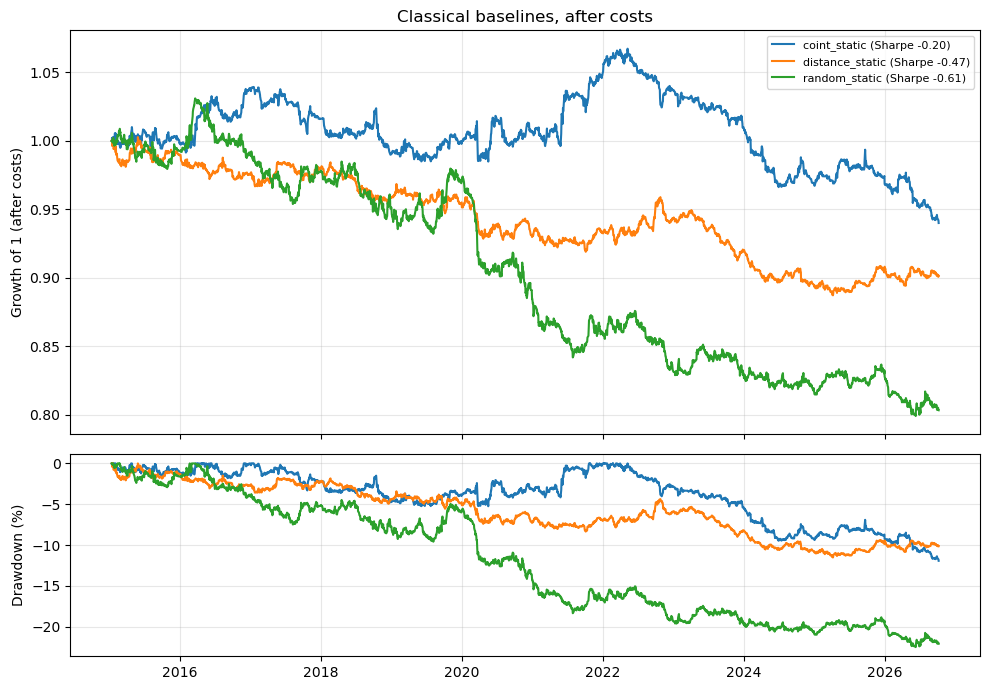

How the cointegration baseline's trades ended:
reason
time          740
stop          224
mean          104
window_end     53
Name: count, dtype: int64


In [25]:
baselines = {}
rows = []
for selector in ["coint", "distance", "random"]:
    name = f"{selector}_static"
    result = get_backtest(data, selector, "static", config, name)
    baselines[selector] = result
    rows.append(metrics_row(name, compute_metrics(result["returns"], result["trades"], nifty_returns, config=config)))
    log_trial(name, result["returns"])

dates = baselines["coint"]["dates"]
rows.append(metrics_row("NIFTY50_buy_and_hold", compute_metrics(nifty_returns.reindex(dates))))
save_table(pd.DataFrame(rows), "baseline_metrics")

curves = {f"{selector}_static": result["returns"] for selector, result in baselines.items()}
plot_equity(curves, "Classical baselines, after costs", "baseline_tearsheet.png")

print("How the cointegration baseline's trades ended:")
print(baselines["coint"]["trades"]["reason"].value_counts())

> **Result.** Every baseline loses money after costs (Sharpe: cointegration −0.20, distance −0.47,
> random −0.61), though cointegration at least beats random pairs. Only about 9% of the
> cointegration trades reach z = 0; two-thirds end on the time stop. Pairs that looked
> mean-reverting in the formation year mostly stopped behaving that way.

## 6.2 How many pairs survive the multiple-testing correction?

In [26]:
windows_table = baselines["coint"]["windows"]
fdr_table = windows_table[["window", "trading_start", "n_universe", "n_tests", "n_raw_pass",
                           "n_fdr_pass", "n_pairs", "n_trades"]].copy()
fdr_table["trading_start"] = fdr_table["trading_start"].dt.strftime("%Y-%m-%d")
save_table(fdr_table, "baseline_fdr_by_window")

print(f"Total tests: {fdr_table['n_tests'].sum()} | raw p < 0.05: {fdr_table['n_raw_pass'].sum()} "
      f"| pass Benjamini-Hochberg: {fdr_table['n_fdr_pass'].sum()}")
johansen_share = baselines["coint"]["pairs"]["johansen_pass"].mean() * 100
print(f"Selected pairs that also pass Johansen's test: {johansen_share:.1f}%")

,window,trading_start,n_universe,n_tests,n_raw_pass,n_fdr_pass,n_pairs,n_trades
0,0,2015-01-13,172,14706,1266,0,20,49
1,1,2015-07-17,170,14365,1944,0,20,62
2,2,2016-01-21,170,14365,1517,16,20,58
3,3,2016-07-27,171,14535,1347,0,20,46
4,4,2017-01-31,177,15576,1603,0,20,46
5,5,2017-08-03,180,16110,1208,2,20,44
6,6,2018-02-05,180,16110,1159,0,20,50
7,7,2018-08-07,185,17020,1126,0,20,62
8,8,2019-02-12,196,19110,1588,119,20,43
9,9,2019-08-22,199,19701,1339,0,20,42


Total tests: 457303 | raw p < 0.05: 33929 | pass Benjamini-Hochberg: 180
Selected pairs that also pass Johansen's test: 100.0%


> **Result.** Benjamini–Hochberg accepts only 180 of 457,303 tests, and none at all in 15 of the 23
> windows. 7.4% of pairs pass the raw test, barely more than the 5% expected by chance. That is why
> pairs are *ranked* by the corrected p-value instead of being *required* to pass it.

## 6.3 Sanity tests
- **One extra day of delay.** If the backtest were accidentally using future prices, trading one day
  later would hurt it badly.
- **Shuffled returns.** Shuffling destroys any real pattern, so the result should be about zero
  minus costs.

In [27]:
delay_config = dict(config)
delay_config["execution_delay"] = 2
shuffle_config = dict(config)
shuffle_config["shuffle_test"] = True

base = baselines["coint"]
delayed = get_backtest(data, "coint", "static", delay_config, "coint_static_delay2")
shuffled = get_backtest(data, "coint", "static", shuffle_config, "coint_static_shuffled")

rows = [
    metrics_row("coint_static (signal t, trade t+1)", compute_metrics(base["returns"], base["trades"])),
    metrics_row("one extra day of delay (trade t+2)", compute_metrics(delayed["returns"], delayed["trades"])),
    metrics_row("shuffled trading-window returns", compute_metrics(shuffled["returns"], shuffled["trades"])),
]
save_table(pd.DataFrame(rows), "baseline_sanity_tests")

  backtest coint_static_delay2: 23 windows, 460 pairs, 1116 trades


  backtest coint_static_shuffled: 23 windows, 460 pairs, 1284 trades


,strategy,annual_return_pct,annual_vol_pct,sharpe,sortino,max_drawdown_pct,trades,hit_rate_pct,avg_holding_days,stop_exit_pct
0,"coint_static (signal t, trade t+1)",-0.54,2.53,-0.20,-0.28,-11.92,1121,45.6,9.9,20.0
1,one extra day of delay (trade t+2),-0.30,2.48,-0.11,-0.16,-14.13,1116,46.4,9.8,20.0
2,shuffled trading-window returns,-0.20,2.61,-0.06,-0.09,-8.73,1284,47.8,9.3,24.5


> **Result.** The delay moved Sharpe from −0.20 to −0.11 and the shuffled version earned −0.06.
> Neither points to a look-ahead bug: there is simply no edge for a delay to destroy.

## 6.4 RQ1: does PCA + clustering find better pairs?
All seven selectors with the static hedge. "Still cointegrated" is an out-of-sample check: the share
of selected pairs that pass the cointegration test again in the trading window.

In [28]:
SELECTORS = ["coint", "sector", "distance", "kmeans", "gmm", "optics", "random"]
rows = []
for selector in SELECTORS:
    name = f"{selector}_static"
    result = get_backtest(data, selector, "static", config, name)
    metrics = compute_metrics(result["returns"], result["trades"], config=config)
    pairs = result["pairs"]
    still_cointegrated = float((pairs["oos_pvalue"] < 0.05).mean()) * 100 if len(pairs) > 0 else 0.0
    rows.append({
        "selector": selector,
        "tests_per_window": int(round(result["windows"]["n_tests"].mean())),
        "pairs_found": len(pairs),
        "still_cointegrated_pct": round(still_cointegrated, 1),
        "sharpe": metrics["sharpe"],
        "max_drawdown_pct": metrics["max_drawdown_pct"],
        "trades": metrics["trades"],
    })
    log_trial(name, result["returns"])
save_table(pd.DataFrame(rows), "selector_comparison")

  loaded saved backtest coint_static


  backtest sector_static: 23 windows, 460 pairs, 1114 trades
  loaded saved backtest distance_static


  backtest kmeans_static: 23 windows, 460 pairs, 1142 trades


  backtest gmm_static: 23 windows, 460 pairs, 1161 trades


  backtest optics_static: 23 windows, 137 pairs, 300 trades
  loaded saved backtest random_static


,selector,tests_per_window,pairs_found,still_cointegrated_pct,sharpe,max_drawdown_pct,trades
0,coint,19883,460,7.6,-0.20,-11.92,1121
1,sector,1466,460,8.3,-0.56,-15.78,1114
2,distance,0,460,7.0,-0.47,-11.52,1172
3,kmeans,2362,460,10.2,-0.16,-11.13,1142
4,gmm,7075,460,7.8,-0.46,-15.08,1161
5,optics,146,137,10.9,0.10,-3.51,300
6,random,0,460,8.0,-0.61,-22.49,712


> **Result.** k-means cuts the tests per window by 88% (19,883 → 2,362) and raises the share of pairs
> that stay cointegrated from 7.6% to 10.2%, with a slightly better Sharpe (−0.16 vs −0.20). OPTICS
> has the best Sharpe (0.10) but finds only 137 pairs in total.

### What PCA and k-means see (latest formation window)

First component explains 5.1% of the variance; the first 10 explain 28.9%


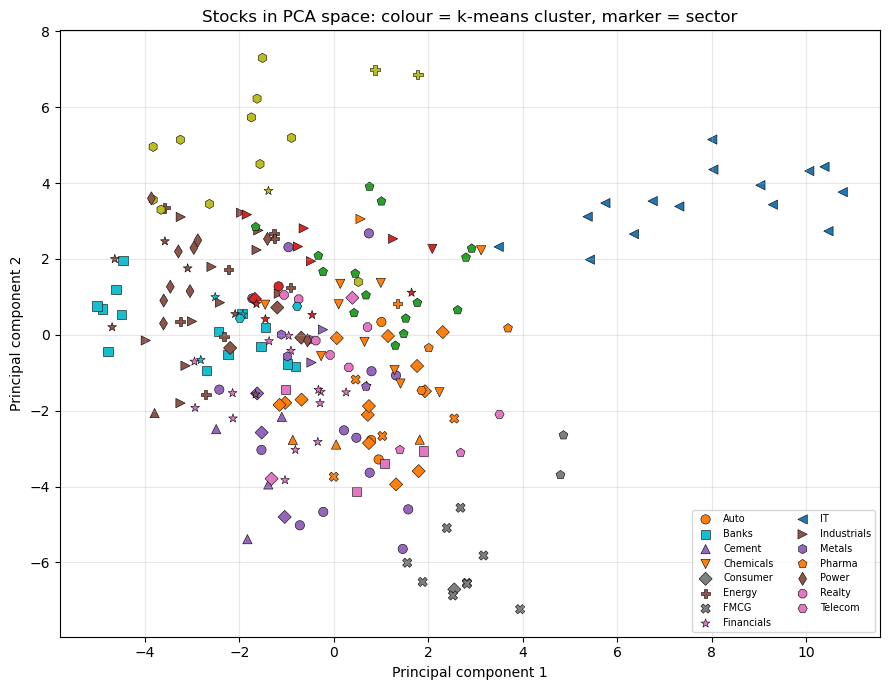

In [29]:
windows = make_windows(len(data["prices"]), config)
window = windows[-1]
log_formation = window_log_prices(data, window, config).iloc[:window["formation_end"] - window["formation_start"]]
tickers = list(log_formation.columns)

_, explained = pca_embedding(log_formation, 30)
print(f"First component explains {explained[0] * 100:.1f}% of the variance; "
      f"the first 10 explain {explained[:10].sum() * 100:.1f}%")

embedding, _ = pca_embedding(log_formation, config["pca_components"])
labels = cluster_kmeans(embedding, config["k_choices"], config["seed"])
sectors = sorted(set(SECTOR_OF.values()))
markers = ["o", "s", "^", "v", "D", "P", "X", "*", "<", ">", "h", "p", "d", "8", "H"]

figure, axis = plt.subplots(figsize=(9, 7))
for s, sector in enumerate(sectors):
    rows = [i for i, ticker in enumerate(tickers) if SECTOR_OF.get(ticker) == sector]
    if rows:
        axis.scatter(embedding[rows, 0], embedding[rows, 1], c=labels[rows], cmap="tab10", vmin=0, vmax=9,
                     marker=markers[s], s=45, edgecolors="black", linewidths=0.4, label=sector)
axis.set_xlabel("Principal component 1")
axis.set_ylabel("Principal component 2")
axis.set_title("Stocks in PCA space: colour = k-means cluster, marker = sector")
axis.legend(fontsize=7, ncol=2)
axis.grid(alpha=0.3)
save_figure(figure, "pca_clusters.png")

## 6.5 RQ3: does a Kalman hedge ratio beat static OLS?
The same k-means pairs with the three hedge models, without any other ML layer.

In [30]:
HEDGES = ["static", "rolling", "kalman"]
hedge_results = {}
rows = []
for hedge in HEDGES:
    name = f"kmeans_{hedge}"
    result = get_backtest(data, "kmeans", hedge, config, name)
    hedge_results[hedge] = result
    metrics = compute_metrics(result["returns"], result["trades"], config=config)
    rows.append({
        "hedge": hedge,
        "sharpe": metrics["sharpe"],
        "annual_return_pct": metrics["annual_return_pct"],
        "max_drawdown_pct": metrics["max_drawdown_pct"],
        "turnover_per_year": metrics["turnover_per_year"],
        "trades": metrics["trades"],
        "hit_rate_pct": metrics["hit_rate_pct"],
        "avg_holding_days": metrics["avg_holding_days"],
        "stop_exit_pct": metrics["stop_exit_pct"],
    })
    log_trial(name, result["returns"])
save_table(pd.DataFrame(rows), "hedge_comparison")

  loaded saved backtest kmeans_static


  backtest kmeans_rolling: 23 windows, 460 pairs, 1359 trades


  backtest kmeans_kalman: 23 windows, 460 pairs, 887 trades


,hedge,sharpe,annual_return_pct,max_drawdown_pct,turnover_per_year,trades,hit_rate_pct,avg_holding_days,stop_exit_pct
0,static,-0.16,-0.42,-11.13,10.0,1142,48.9,10.4,19.5
1,rolling,-0.69,-2.18,-26.15,11.9,1359,51.8,9.6,4.3
2,kalman,-0.00,-0.01,-6.59,7.7,887,55.4,3.0,3.8


> **Result.** Kalman beats static OLS on every column: Sharpe 0.00 vs −0.16, max drawdown −6.6% vs
> −11.1%, and less trading (7.7× vs 10.0× the capital a year). Rolling OLS is the worst (−0.69):
> 60 days is too short, so its β is noisy.

### OU description of the selected pairs, and β over time for three pairs

,statistic,mean,median,p10,p90
0,half_life,6.3302,6.0335,5.1864,7.7788
1,sigma_eq,0.0560,0.0505,0.0332,0.0815
2,ar_b,0.8935,0.8915,0.8749,0.9147
3,hurst,0.3237,0.3195,0.2450,0.4066
4,beta,0.9758,0.8555,0.4641,1.6462


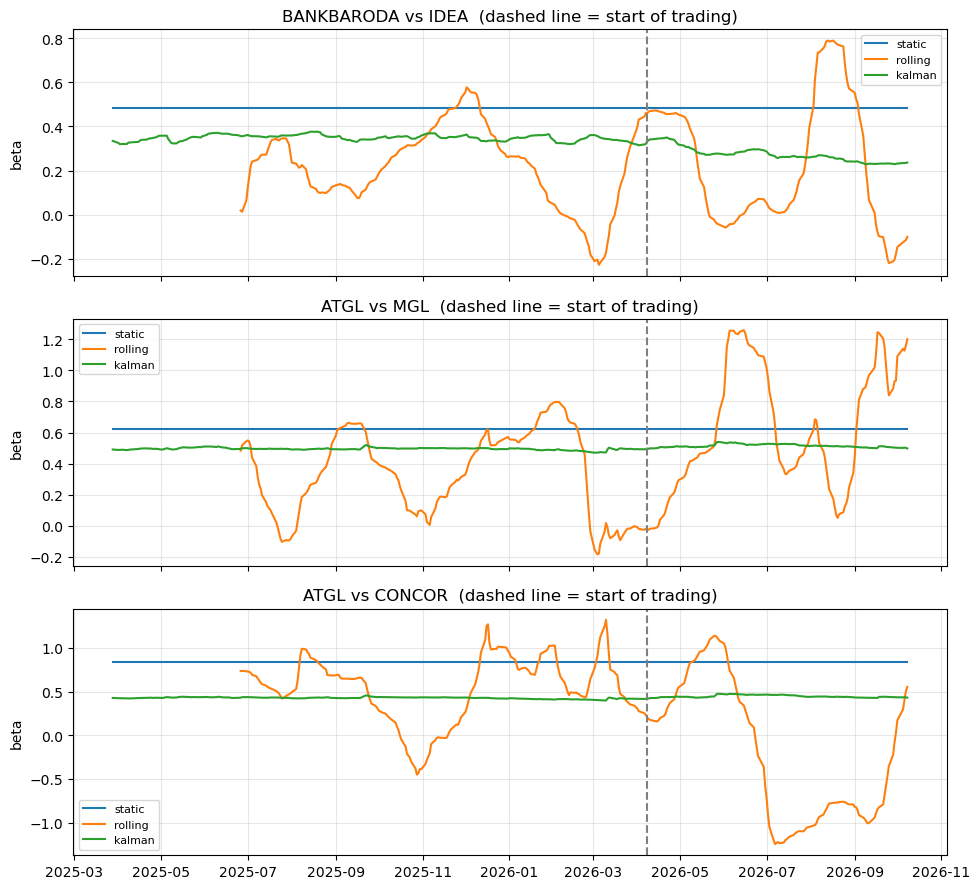

In [31]:
pairs = hedge_results["static"]["pairs"]
rows = []
for column in ["half_life", "sigma_eq", "ar_b", "hurst", "beta"]:
    values = pairs[column].dropna()
    rows.append({"statistic": column, "mean": round(float(values.mean()), 4),
                 "median": round(float(values.median()), 4),
                 "p10": round(float(values.quantile(0.10)), 4), "p90": round(float(values.quantile(0.90)), 4)})
save_table(pd.DataFrame(rows), "ou_summary")

window_id = len(windows) - 1
window = windows[window_id]
n_formation = window["formation_end"] - window["formation_start"]
log_prices = window_log_prices(data, window, config)
example_pairs = pairs[pairs["window"] == window_id].head(3)

figure, axes = plt.subplots(len(example_pairs), 1, figsize=(10, 3 * len(example_pairs)), sharex=True)
for axis, a, b in zip(axes, example_pairs["a"], example_pairs["b"]):
    for hedge in HEDGES:
        signal = compute_signal(hedge, log_prices[a].values, log_prices[b].values, n_formation, config)
        axis.plot(log_prices.index, signal["beta"], label=hedge)
    axis.axvline(log_prices.index[n_formation], color="grey", linestyle="--")
    axis.set_title(f"{a} vs {b}  (dashed line = start of trading)")
    axis.set_ylabel("beta")
    axis.legend(fontsize=8)
    axis.grid(alpha=0.3)
save_figure(figure, "hedge_ratio_paths.png")

---
# 7. ML replacement #3: meta-labeling (RQ2)

The z-score rule proposes every trade. A classifier then predicts whether each proposed trade will
work, and the system skips or shrinks the weak ones.

- **One sample per trade**, with the 20 features from Part 5.1.
- **Two labels:** `barrier` = 1 if the spread reached its mean before the stop or time limit;
  `pnl` = 1 if the trade made money after costs (the one used in the final system).
- **Seven models:** logistic regression, GDA (LDA), naive Bayes, RBF SVM, random forest, LightGBM
  and a small neural network (MLP).
- **Walk-forward training:** the trades of window $w$ are predicted by a model trained only on
  trades from earlier windows.
- **Purged, embargoed cross-validation** picks each model's settings inside that training data. A
  training trade is dropped if its holding period overlaps the validation trades, or if it starts
  right after them, so a trade's outcome cannot leak into the validation set.
- **Using the probability p:** keep the top 100%, 80%, 60% or 40% of trades (whichever had the best
  after-cost Sharpe in training), and size each kept trade by $p/\bar p$, capped at 1.5.

In [32]:
MODEL_NAMES = ["logistic", "gda", "naive_bayes", "svm", "random_forest", "lightgbm", "mlp"]

# small grids: with only a few hundred samples, simple models should win
PARAM_GRID = {
    "logistic": [{"C": 0.01}, {"C": 0.1}, {"C": 1.0}],
    "gda": [{}],
    "naive_bayes": [{}],
    "svm": [{"C": 0.1}, {"C": 1.0}],
    "random_forest": [{"max_depth": 3}, {"max_depth": 5}],
    "lightgbm": [{"num_leaves": 4, "n_estimators": 100}, {"num_leaves": 8, "n_estimators": 200}],
    "mlp": [{"alpha": 0.01}, {"alpha": 1.0}],
}


def make_labels(trades, label_type):
    """1 = the trade worked, 0 = it did not."""
    if label_type == "barrier":
        return (trades["reason"] == "mean").values.astype(int)
    return (trades["net_pnl"] > 0).values.astype(int)


def make_model(name, params, seed):
    """One classifier. Missing values are filled and features are scaled first."""
    if name == "logistic":
        classifier = LogisticRegression(C=params["C"], penalty="l2", max_iter=1000)
    elif name == "gda":
        classifier = LinearDiscriminantAnalysis()       # Gaussian discriminant analysis, shared covariance
    elif name == "naive_bayes":
        classifier = GaussianNB()
    elif name == "svm":
        classifier = SVC(C=params["C"], kernel="rbf", probability=True, random_state=seed)
    elif name == "random_forest":
        classifier = RandomForestClassifier(n_estimators=200, max_depth=params["max_depth"],
                                            min_samples_leaf=10, random_state=seed)
    elif name == "lightgbm":
        classifier = LGBMClassifier(n_estimators=params["n_estimators"], num_leaves=params["num_leaves"],
                                    learning_rate=0.03, min_child_samples=20, subsample=0.8,
                                    subsample_freq=1, colsample_bytree=0.8, random_state=seed,
                                    verbose=-1, n_jobs=1)
    else:
        classifier = MLPClassifier(hidden_layer_sizes=(16, 8), alpha=params["alpha"], max_iter=500,
                                   random_state=seed)
    return Pipeline([("fill_missing", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("classifier", classifier)])

In [33]:
def purged_cv_splits(entry_dates, exit_dates, n_folds, embargo_days):
    """Time-ordered folds. A training trade is dropped if it overlaps the validation
    period (purge) or starts within `embargo_days` after it (embargo)."""
    order = np.argsort(entry_dates)
    fold_size = len(entry_dates) // n_folds
    embargo = np.timedelta64(int(embargo_days), "D")
    splits = []
    for fold in range(n_folds):
        stop = len(entry_dates) if fold == n_folds - 1 else (fold + 1) * fold_size   # last fold takes the rest
        validation = order[fold * fold_size:stop]
        validation_start = entry_dates[validation].min()
        validation_end = exit_dates[validation].max()
        in_validation = set(validation.tolist())

        train = []
        for i in order:
            if i in in_validation:
                continue
            overlaps = entry_dates[i] <= validation_end and exit_dates[i] >= validation_start
            in_embargo = validation_end < entry_dates[i] <= validation_end + embargo
            if not overlaps and not in_embargo:
                train.append(i)
        splits.append((np.array(train, dtype=int), validation))
    return splits


def cv_predictions(name, params, X, y, splits, seed):
    """Out-of-fold probabilities: each trade is predicted by a model that did not see it."""
    predictions = np.full(len(y), np.nan)
    for train, validation in splits:
        if len(train) < 20 or len(set(y[train])) < 2:
            continue
        model = make_model(name, params, seed)
        model.fit(X[train], y[train])
        predictions[validation] = model.predict_proba(X[validation])[:, 1]
    return predictions


def tune_model(name, X, y, splits, seed):
    """The settings with the lowest cross-validated log-loss."""
    best_loss = np.inf
    best_params = PARAM_GRID[name][0]
    best_predictions = np.full(len(y), np.nan)
    for params in PARAM_GRID[name]:
        predictions = cv_predictions(name, params, X, y, splits, seed)
        known = ~np.isnan(predictions)
        if known.sum() == 0 or len(set(y[known])) < 2:
            continue
        loss = log_loss(y[known], np.clip(predictions[known], 0.001, 0.999))
        if loss < best_loss:
            best_loss = loss
            best_params = params
            best_predictions = predictions
    return best_params, best_predictions


def choose_threshold(probabilities, trade_ids, daily, dates, config):
    """Keep the top share of trades by p that gave the best after-cost Sharpe in training.
    Returns (threshold, average p of the kept trades)."""
    known = ~np.isnan(probabilities)
    if known.sum() < 20:
        return 0.0, 1.0
    best_sharpe = -np.inf
    best_threshold = 0.0
    for keep_share in config["keep_share_choices"]:
        threshold = 0.0
        if keep_share < 1.0:
            threshold = float(np.quantile(probabilities[known], 1.0 - keep_share))
        kept = known & (probabilities > threshold)
        weights = {trade_id: 1.0 for trade_id in trade_ids[kept]}
        sharpe = sharpe_ratio(portfolio_returns(daily, dates, config, weights))
        if sharpe > best_sharpe:
            best_sharpe = sharpe
            best_threshold = threshold
    kept = known & (probabilities > best_threshold)
    return best_threshold, float(probabilities[kept].mean())

In [34]:
def walk_forward_predict(result, model_name, config):
    """Out-of-sample probability for every trade, from a model trained on earlier windows only."""
    trades = result["trades"]
    X = trades[FEATURE_NAMES].values.astype(float)
    y = make_labels(trades, config["label_type"])
    trade_ids = trades["trade_id"].values
    window_of_trade = trades["window"].values
    entry_dates = trades["signal_date"].values
    exit_dates = trades["exit_date"].values

    probability = np.full(len(trades), np.nan)
    threshold = np.full(len(trades), np.nan)
    reference = np.full(len(trades), np.nan)

    for window_id in range(config["min_train_windows"], len(result["windows"])):
        train = np.where(window_of_trade < window_id)[0]
        test = np.where(window_of_trade == window_id)[0]
        if len(test) == 0 or len(train) < 50 or len(set(y[train])) < 2:
            continue

        # embargo: at least the longest holding period seen in training (in calendar days)
        embargo_days = max(config["embargo_days"], int(trades["holding_days"].values[train].max() * 1.5))
        splits = purged_cv_splits(entry_dates[train], exit_dates[train], config["cv_folds"], embargo_days)
        params, cv_probabilities = tune_model(model_name, X[train], y[train], splits, config["seed"])

        trading_start = result["windows"]["trading_start"].values[window_id]
        train_dates = result["dates"][result["dates"] < trading_start]
        train_daily = result["daily"][result["daily"]["trade_id"].isin(trade_ids[train])]
        tau, ref = choose_threshold(cv_probabilities, trade_ids[train], train_daily, train_dates, config)

        model = make_model(model_name, params, config["seed"])
        model.fit(X[train], y[train])
        probability[test] = model.predict_proba(X[test])[:, 1]
        threshold[test] = tau
        reference[test] = ref

    return pd.DataFrame({"trade_id": trade_ids, "window": window_of_trade, "label": y,
                         "probability": probability, "threshold": threshold, "reference": reference})


def filter_weights(predictions, config, sized):
    """{trade_id: size} for trades with p above the threshold. sized=True: size = p / average p."""
    weights = {}
    for row in predictions.itertuples():
        if np.isnan(row.probability) or row.probability <= row.threshold:
            continue
        size = min(row.probability / row.reference, config["size_cap"]) if sized else 1.0
        weights[row.trade_id] = size
    return weights

## 7.1 Compare the seven models
Each model is judged statistically (AUC: 0.5 = guessing, 1 = perfect; Brier score: lower is better)
and economically (Sharpe without the filter, with the filter, and with the filter plus sizing).

In [35]:
primary = get_backtest(data, "kmeans", "kalman", config, "kmeans_kalman")
print(f"Primary model: k-means pairs with the Kalman hedge -> {len(primary['trades'])} trades")


def compare_models(result, config, label_type):
    """Train every classifier walk-forward and measure it. Returns (table, predictions)."""
    label_config = dict(config)
    label_config["label_type"] = label_type
    trades = result["trades"]
    daily = result["daily"]
    rows = []
    predictions_by_model = {}
    for model_name in MODEL_NAMES:
        print(f"  training {model_name} ...")
        predictions = walk_forward_predict(result, model_name, label_config)
        predictions_by_model[model_name] = predictions
        known = predictions[predictions["probability"].notna()]
        start = result["windows"]["trading_start"].values[int(known["window"].min())]
        dates = result["dates"][result["dates"] >= start]

        all_weights = {trade_id: 1.0 for trade_id in known["trade_id"].values}
        filtered_weights = filter_weights(predictions, label_config, sized=False)
        sized_weights = filter_weights(predictions, label_config, sized=True)
        filtered_returns = portfolio_returns(daily, dates, label_config, filtered_weights)
        unfiltered = compute_metrics(portfolio_returns(daily, dates, label_config, all_weights), trades, weights=all_weights)
        filtered = compute_metrics(filtered_returns, trades, weights=filtered_weights)
        sized = compute_metrics(portfolio_returns(daily, dates, label_config, sized_weights), trades, weights=sized_weights)
        log_trial(f"meta_{label_type}_{model_name}", filtered_returns)

        taken = known[known["probability"] > known["threshold"]]
        precision = float(taken["label"].mean()) if len(taken) > 0 else np.nan
        rows.append({
            "model": model_name,
            "auc": round(roc_auc_score(known["label"], known["probability"]), 3),
            "brier": round(brier_score_loss(known["label"], known["probability"]), 4),
            "base_rate": round(float(known["label"].mean()), 3),
            "precision_taken": round(precision, 3),
            "trades_all": unfiltered["trades"],
            "trades_taken": filtered["trades"],
            "sharpe_unfiltered": unfiltered["sharpe"],
            "sharpe_filtered": filtered["sharpe"],
            "sharpe_filtered_sized": sized["sharpe"],
            "max_dd_unfiltered_pct": unfiltered["max_drawdown_pct"],
            "max_dd_filtered_pct": filtered["max_drawdown_pct"],
        })
    return pd.DataFrame(rows), predictions_by_model

  loaded saved backtest kmeans_kalman
Primary model: k-means pairs with the Kalman hedge -> 887 trades


Label: barrier
  training logistic ...


  training gda ...


  training naive_bayes ...


  training svm ...


  training random_forest ...


  training lightgbm ...


... (6 outputs left out)

  training random_forest ...


  training lightgbm ...


  training mlp ...


,model,auc,brier,base_rate,precision_taken,trades_all,trades_taken,sharpe_unfiltered,sharpe_filtered,sharpe_filtered_sized,max_dd_unfiltered_pct,max_dd_filtered_pct
0,logistic,0.537,0.2469,0.556,0.565,671,499,-0.16,0.04,0.06,-5.62,-4.95
1,gda,0.542,0.2604,0.556,0.573,671,358,-0.16,-0.11,-0.07,-5.62,-5.49
2,naive_bayes,0.563,0.2881,0.556,0.571,671,585,-0.16,-0.01,0.19,-5.62,-4.30
3,svm,0.503,0.2478,0.556,0.568,671,555,-0.16,-0.22,-0.22,-5.62,-6.90
4,random_forest,0.512,0.2488,0.556,0.538,671,520,-0.16,-0.36,-0.31,-5.62,-6.72
5,lightgbm,0.514,0.2538,0.556,0.555,671,530,-0.16,0.00,0.03,-5.62,-4.35
6,mlp,0.525,0.3177,0.556,0.543,671,497,-0.16,-0.42,-0.27,-5.62,-6.81


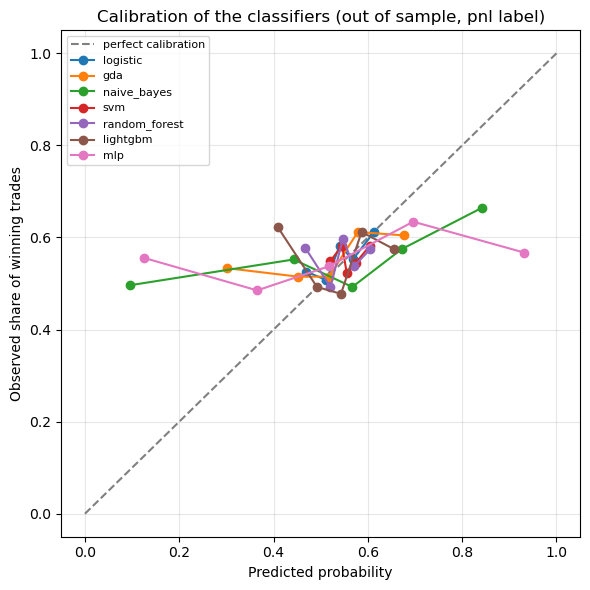

In [36]:
for label_type in ["barrier", "pnl"]:
    print(f"Label: {label_type}")
    table, predictions_by_model = compare_models(primary, config, label_type)
    save_table(table, f"meta_model_comparison_{label_type}")

# calibration plot for the label the system uses (pnl): predicted p against what really happened
figure, axis = plt.subplots(figsize=(6, 6))
axis.plot([0, 1], [0, 1], color="grey", linestyle="--", label="perfect calibration")
for model_name, predictions in predictions_by_model.items():
    known = predictions[predictions["probability"].notna()]
    observed, predicted = calibration_curve(known["label"], known["probability"], n_bins=5, strategy="quantile")
    axis.plot(predicted, observed, marker="o", label=model_name)
axis.set_xlabel("Predicted probability")
axis.set_ylabel("Observed share of winning trades")
axis.set_title("Calibration of the classifiers (out of sample, pnl label)")
axis.legend(fontsize=8)
axis.grid(alpha=0.3)
save_figure(figure, "meta_calibration.png")

> **Result (pnl label).** Out-of-sample AUC is only 0.50–0.56, so the classifiers have very little
> skill (naive Bayes 0.563, logistic regression 0.537). Even so, the logistic filter with sizing
> lifts Sharpe from −0.16 to 0.06 and cuts the max drawdown from −5.6% to −4.9%.
>
> The barrier label is nearly always 1 with a Kalman hedge (93% of trades reach z = 0, because the
> filter adapts), so it says little about profit.

### Which features matter?
Logistic regression on all trades, with standardised coefficients (largest effect first). This only
describes the data; it is not used for trading.

In [37]:
X = primary["trades"][FEATURE_NAMES].values.astype(float)
y = make_labels(primary["trades"], config["label_type"])
model = make_model("logistic", {"C": 0.1}, config["seed"])
model.fit(X, y)
coefficients = pd.DataFrame({"feature": FEATURE_NAMES,
                             "coefficient": np.round(model.named_steps["classifier"].coef_[0], 3)})
coefficients = coefficients.sort_values("coefficient", key=lambda column: column.abs(), ascending=False)
save_table(coefficients, "meta_logistic_coefficients")

,feature,coefficient
4,sigma_eq,0.289
17,vix_level,-0.203
19,nifty_return_20d,-0.163
16,log_liquidity,-0.154
12,beta_drift,0.109
6,hurst,-0.102
13,same_sector,0.101
10,correlation_60d,0.092
2,distance_to_stop,-0.062
0,entry_abs_z,0.062


---
# 8. ML replacement #4: deep learning (RQ4)

Can a neural network forecast how far a spread will move back better than the OU formula?

- **Task:** from the last 60 days of a pair's z-score, forecast the change in z over the next 5 days.
- **Input:** the 60 z-scores (clipped to ±6), plus the OU reversion share $1 - e^{-5\theta}$.
- **TCN (temporal convolutional network):** 4 layers of *causal* 1-D convolutions with kernel 3 and
  dilations 1, 2, 4, 8. Each output sees the last 31 days and never the future.
- **Baselines it must beat:** no change; AR(1) (one linear regression on today's z); OU,
  $z\,(e^{-5\theta}-1)$.
- **Training:** from scratch in every window, on formation-year samples only. The last 20% of
  them is a validation set for early stopping.
- **Trading test:** take a trade only if the forecast move, converted to basis points of the pair's
  capital, is bigger than the trading cost:

$$\frac{-\operatorname{sign}(z)\;\widehat{\Delta z}\;\sigma}{1+\beta}\times 10^4 \;>\; \frac{28}{2}\ \text{bps}$$

In [38]:
class TCN(nn.Module):
    """Dilated causal convolutions, then a linear output layer."""

    def __init__(self, channels, layers, dropout):
        super().__init__()
        self.convolutions = nn.ModuleList()
        self.paddings = []
        in_channels = 1
        for i in range(layers):
            dilation = 2 ** i                 # 1, 2, 4, 8: each layer looks further back
            padding = 2 * dilation            # kernel size 3
            self.convolutions.append(nn.Conv1d(in_channels, channels, kernel_size=3,
                                               dilation=dilation, padding=padding))
            self.paddings.append(padding)
            in_channels = channels
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(channels + 1, 1)

    def forward(self, sequence, extra):
        x = sequence.unsqueeze(1)                       # (batch, 1, lookback)
        for convolution, padding in zip(self.convolutions, self.paddings):
            x = convolution(x)
            x = x[:, :, :-padding]                      # cut the end so no layer sees the future
            x = self.dropout(torch.relu(x))
        combined = torch.cat([x[:, :, -1], extra], dim=1)   # features of the latest day + OU share
        return self.output(combined).squeeze(1)

In [39]:
def build_samples(signals, config):
    """Cut every pair's z-score series of one window into (history, target) samples.

    train / validation: inside the formation window (validation = its last 20%);
    test: the trading days. Returns three dictionaries with X, extra, y, pair, t.
    """
    lookback = config["lookback"]
    horizon = config["horizon"]
    parts = {name: {"X": [], "extra": [], "y": [], "pair": [], "t": []} for name in ["train", "validation", "test"]}

    for pair_index, signal in enumerate(signals):
        z = np.clip(signal["z"], -6, 6)
        n_formation = signal["n_formation"]
        theta = signal["theta"]
        reversion_share = 0.0 if np.isnan(theta) else 1.0 - np.exp(-theta * horizon)
        n_usable = n_formation - horizon - (lookback - 1)
        validation_start = n_formation - horizon - int(0.2 * n_usable)

        for t in range(lookback - 1, len(z)):
            history = z[t - lookback + 1:t + 1]
            if np.isnan(history).any():
                continue
            target = np.nan
            if t + horizon < len(z):
                target = z[t + horizon] - z[t]

            if t >= n_formation:
                part = "test"
            elif t + horizon >= n_formation:
                continue                       # target would reach into the trading window
            elif t >= validation_start:
                part = "validation"
            elif t + horizon < validation_start:
                part = "train"
            else:
                continue                       # gap so training targets do not overlap validation
            parts[part]["X"].append(history)
            parts[part]["extra"].append([reversion_share])
            parts[part]["y"].append(target)
            parts[part]["pair"].append(pair_index)
            parts[part]["t"].append(t)

    for part in parts.values():
        part["X"] = np.array(part["X"], dtype=np.float32).reshape(-1, lookback)
        part["extra"] = np.array(part["extra"], dtype=np.float32).reshape(-1, 1)
        part["y"] = np.array(part["y"], dtype=np.float32)
        part["pair"] = np.array(part["pair"], dtype=int)
        part["t"] = np.array(part["t"], dtype=int)
    return parts["train"], parts["validation"], parts["test"]


def train_network(network, train, validation, config):
    """Adam + mean-squared error; stop when the validation loss stops improving."""
    optimizer = torch.optim.Adam(network.parameters(), lr=config["learning_rate"])
    loss_function = nn.MSELoss()
    X = torch.from_numpy(train["X"])
    E = torch.from_numpy(train["extra"])
    y = torch.from_numpy(train["y"])
    X_val = torch.from_numpy(validation["X"])
    E_val = torch.from_numpy(validation["extra"])
    y_val = torch.from_numpy(validation["y"])

    best_loss = np.inf
    best_weights = copy.deepcopy(network.state_dict())
    epochs_without_improvement = 0
    for _ in range(config["epochs"]):
        network.train()
        order = torch.randperm(len(X))
        for start in range(0, len(X), config["batch_size"]):
            batch = order[start:start + config["batch_size"]]
            optimizer.zero_grad()
            loss = loss_function(network(X[batch], E[batch]), y[batch])
            loss.backward()
            optimizer.step()

        network.eval()
        with torch.no_grad():
            validation_loss = loss_function(network(X_val, E_val), y_val).item()
        if validation_loss < best_loss:
            best_loss = validation_loss
            best_weights = copy.deepcopy(network.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= config["patience"]:
                break
    network.load_state_dict(best_weights)
    return network

In [40]:
def run_forecasters(result, config):
    """TCN and the three baselines in every window. One row per (pair, trading day)."""
    tables = []
    for window_id in range(len(result["windows"])):
        window_signals = [signal for signal in result["signals"] if signal["window"] == window_id]
        if not window_signals:
            continue
        train, validation, test = build_samples(window_signals, config)
        if len(train["y"]) < 100 or len(validation["y"]) < 20 or len(test["y"]) == 0:
            continue

        z_now = test["X"][:, -1]
        a_names = [window_signals[i]["a"] for i in test["pair"]]
        b_names = [window_signals[i]["b"] for i in test["pair"]]
        table = pd.DataFrame({"window": window_id, "a": a_names, "b": b_names, "t": test["t"],
                              "z": z_now, "target": test["y"]})

        table["pred_zero"] = 0.0
        slope, intercept = np.polyfit(train["X"][:, -1], train["y"], 1)
        table["pred_ar1"] = intercept + slope * z_now
        table["pred_ou"] = -z_now * test["extra"][:, 0]

        torch.manual_seed(config["seed"] + window_id)
        network = train_network(TCN(config["channels"], config["layers"], config["dropout"]),
                                train, validation, config)
        network.eval()
        with torch.no_grad():
            table["pred_tcn"] = network(torch.from_numpy(test["X"]), torch.from_numpy(test["extra"])).numpy()
        tables.append(table)
        print(f"    window {window_id}: trained on {len(train['y'])} samples")
    return pd.concat(tables, ignore_index=True)


def get_forecasts(result, config):
    """Load saved forecasts made with the same settings, or train the TCN and save them."""
    name = result["name"]
    saved = load_pickle(f"forecasts_{name}")
    if saved is not None and saved["config"] == config:
        print(f"  loaded saved forecasts for {name}")
        return saved["forecasts"]
    print(f"  training the TCN for {name} ...")
    forecasts = run_forecasters(result, config)
    save_pickle({"config": config, "forecasts": forecasts}, f"forecasts_{name}")
    return forecasts


def gate_weights(result, forecasts, column, config):
    """{trade_id: 1.0} for trades whose forecast reversion beats the cost."""
    cost_bps = config["pair_cost_bps"] / 2.0          # the pair's capital is two legs
    # (window, a, b, day) -> forecast change in z
    keys = zip(forecasts["window"], forecasts["a"], forecasts["b"], forecasts["t"])
    lookup = dict(zip(keys, forecasts[column]))

    weights = {}
    for trade in result["trades"].itertuples():
        key = (trade.window, trade.a, trade.b, trade.signal_index)
        if key not in lookup:
            continue
        reversion_z = -np.sign(trade.entry_z) * lookup[key]       # positive = towards the mean
        expected_bps = reversion_z * trade.scale / (1.0 + trade.beta) * 10000
        if expected_bps > cost_bps:
            weights[trade.trade_id] = 1.0
    return weights

## 8.1 Forecast accuracy

  training the TCN for kmeans_kalman ...


    window 0: trained on 2320 samples


    window 1: trained on 2320 samples


    window 2: trained on 2320 samples


    window 3: trained on 2320 samples


    window 4: trained on 2320 samples


... (15 outputs left out)

    window 20: trained on 2320 samples


    window 21: trained on 2320 samples


    window 22: trained on 2320 samples


,forecaster,rmse,rmse_entry_zone
0,zero,1.1555,3.1022
1,ar1,0.8201,1.2623
2,ou,0.9408,2.0316
3,tcn,0.8461,1.4269


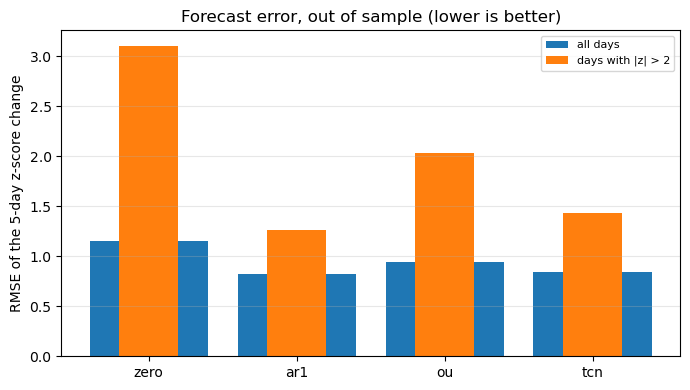

In [41]:
forecasts = get_forecasts(primary, config)

known = forecasts[forecasts["target"].notna()]
entry_zone = known[known["z"].abs() > config["entry_z"]]       # the days on which trades open
rows = []
for name in ["zero", "ar1", "ou", "tcn"]:
    error = known[f"pred_{name}"] - known["target"]
    zone_error = entry_zone[f"pred_{name}"] - entry_zone["target"]
    rows.append({"forecaster": name,
                 "rmse": round(float(np.sqrt((error ** 2).mean())), 4),
                 "rmse_entry_zone": round(float(np.sqrt((zone_error ** 2).mean())), 4)})
forecast_table = pd.DataFrame(rows)
save_table(forecast_table, "dl_forecast_metrics")

figure, axis = plt.subplots(figsize=(7, 4))
axis.bar(forecast_table["forecaster"], forecast_table["rmse"], label="all days")
axis.bar(forecast_table["forecaster"], forecast_table["rmse_entry_zone"], width=0.4, label="days with |z| > 2")
axis.set_ylabel("RMSE of the 5-day z-score change")
axis.set_title("Forecast error, out of sample (lower is better)")
axis.legend(fontsize=8)
axis.grid(alpha=0.3, axis="y")
save_figure(figure, "dl_forecast_rmse.png")

> **Result.** The TCN beats the no-change and OU forecasts (RMSE 0.846 vs 0.941 for OU), but a
> one-line AR(1) regression beats it (0.820).

## 8.2 Trading test: take a trade only if the forecast beats the cost

In [42]:
all_metrics = compute_metrics(primary["returns"], primary["trades"])
rows = [{"gate": "none (every trade)", "sharpe": all_metrics["sharpe"],
         "max_drawdown_pct": all_metrics["max_drawdown_pct"], "trades": all_metrics["trades"],
         "hit_rate_pct": all_metrics["hit_rate_pct"]}]
for name in ["ar1", "ou", "tcn"]:
    weights = gate_weights(primary, forecasts, f"pred_{name}", config)
    returns = portfolio_returns(primary["daily"], primary["dates"], config, weights)
    gated = compute_metrics(returns, primary["trades"], weights=weights)
    rows.append({"gate": name, "sharpe": gated["sharpe"], "max_drawdown_pct": gated["max_drawdown_pct"],
                 "trades": gated["trades"], "hit_rate_pct": gated["hit_rate_pct"]})
    log_trial(f"dl_gate_{name}", returns)
save_table(pd.DataFrame(rows), "dl_trading_test")

,gate,sharpe,max_drawdown_pct,trades,hit_rate_pct
0,none (every trade),-0.0,-6.59,887,55.4
1,ar1,-0.0,-6.59,887,55.4
2,ou,-0.0,-6.59,887,55.4
3,tcn,-0.0,-6.59,887,55.4


> **Result.** The gate never blocks a trade: the forecast moves are worth far more than the 14 bps
> hurdle, so every trade passes and the Sharpe does not change. Realised profit is much smaller
> than forecast (about 50 bps per trade before costs).

---
# 9. Final evaluation

The full system puts the four ML parts together:

```text
PCA + k-means pairs → Kalman hedge → meta-labeler (logistic, sized by p) → TCN cost gate
```

All tables start in **February 2018**, the first window in which the meta-labeler has 6 windows of
past trades to learn from. Every row of a table uses the same dates.

Each ML layer returns `{trade_id: size}`. A trade is taken only if every layer keeps it, and the
sizes are multiplied. "Break-even costs" is profit before costs ÷ costs: how many times higher costs
could be before the profit disappears.

In [43]:
def all_trade_weights(result, first_window):
    """Every trade from `first_window` onwards, at full size."""
    trades = result["trades"]
    kept = trades[trades["window"] >= first_window]
    return {trade_id: 1.0 for trade_id in kept["trade_id"].values}


def combine_weights(weights, other):
    """Keep the trades that are in both dictionaries and multiply their sizes."""
    return {trade_id: size * other[trade_id] for trade_id, size in weights.items() if trade_id in other}


def column_returns(daily, dates, config, weights, column):
    """Daily portfolio returns of one column of the daily table: net, gross or cost."""
    table = pd.DataFrame({"trade_id": daily["trade_id"], "date": daily["date"], "net": daily[column]})
    return portfolio_returns(table, dates, config, weights)


def run_system(data, config, selector, hedge, use_meta, use_dl, name):
    """Backtest one configuration and apply the ML layers that are switched on."""
    result = get_backtest(data, selector, hedge, config, name)
    first_window = config["min_train_windows"]
    weights = all_trade_weights(result, first_window)
    if use_meta:
        predictions = walk_forward_predict(result, "logistic", config)
        weights = combine_weights(weights, filter_weights(predictions, config, sized=True))
    if use_dl:
        forecasts = get_forecasts(result, config)
        weights = combine_weights(weights, gate_weights(result, forecasts, "pred_tcn", config))

    start = result["windows"]["trading_start"].values[first_window]
    dates = result["dates"][result["dates"] >= start]
    return {"result": result, "weights": weights, "dates": dates,
            "net": column_returns(result["daily"], dates, config, weights, "net"),
            "gross": column_returns(result["daily"], dates, config, weights, "gross"),
            "cost": column_returns(result["daily"], dates, config, weights, "cost")}


def system_metrics(system, config):
    """Standard metrics plus gross Sharpe and the break-even cost multiple."""
    metrics = compute_metrics(system["net"], system["result"]["trades"], nifty_returns, system["weights"], config)
    metrics["gross_sharpe"] = round(sharpe_ratio(system["gross"]), 2)
    metrics["break_even_cost_x"] = round(float(system["gross"].sum() / system["cost"].sum()), 2)
    metrics["eval_start"] = str(system["dates"][0].date())
    return metrics

## 9.1 The full system against the benchmarks

In [44]:
systems = {}
systems["Full ML system"] = run_system(data, config, "kmeans", "kalman", True, True, "kmeans_kalman")
systems["Classical baseline (brute force + FDR, static OLS)"] = run_system(
    data, config, "coint", "static", False, False, "coint_static")
systems["Random pairs (null), static OLS"] = run_system(data, config, "random", "static", False, False, "random_static")

rows = []
for label, system in systems.items():
    rows.append(metrics_row(label, system_metrics(system, config)))
    log_trial(f"final_{label}", system["net"])
nifty = compute_metrics(nifty_returns.reindex(systems["Full ML system"]["dates"]).fillna(0.0))
nifty["eval_start"] = str(systems["Full ML system"]["dates"][0].date())
rows.append(metrics_row("NIFTY 50 buy and hold (context only)", nifty))
save_table(pd.DataFrame(rows), "final_summary")

  loaded saved backtest kmeans_kalman


  loaded saved forecasts for kmeans_kalman
  loaded saved backtest coint_static
  loaded saved backtest random_static


,strategy,annual_return_pct,annual_vol_pct,sharpe,sortino,max_drawdown_pct,trades,hit_rate_pct,avg_holding_days,stop_exit_pct,turnover_per_year,corr_with_nifty,gross_sharpe,break_even_cost_x,eval_start
0,Full ML system,0.08,1.41,0.06,0.09,-4.88,499.0,56.5,2.9,4.8,5.9,0.189,0.38,1.20,2018-02-05
1,"Classical baseline (brute force + FDR, static ...",-0.78,2.55,-0.29,-0.41,-11.92,816.0,46.0,9.6,21.6,9.6,0.103,0.09,0.24,2018-02-05
2,"Random pairs (null), static OLS",-2.21,3.10,-0.70,-0.95,-18.86,532.0,47.2,23.7,20.1,6.3,0.154,-0.40,-1.34,2018-02-05
3,NIFTY 50 buy and hold (context only),8.91,16.91,0.59,0.81,-38.44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2018-02-05


> **Result.** Full ML system: Sharpe 0.06 (0.38 before costs), max drawdown −4.9%, 499 trades,
> break-even at 1.2× today's costs. Classical baseline: −0.29 with a −11.9% drawdown. Random pairs:
> −0.70.

## 9.2 Ablation: remove one part at a time

In [45]:
# label, selector, hedge, meta-labeler on, TCN gate on
setups = [
    ("Full system", "kmeans", "kalman", True, True),
    ("- clustering (brute force + FDR)", "coint", "kalman", True, True),
    ("- Kalman (static OLS)", "kmeans", "static", True, True),
    ("- meta-labeler", "kmeans", "kalman", False, True),
    ("- DL forecaster", "kmeans", "kalman", True, False),
]
rows = []
ablation_systems = {}
for label, selector, hedge, use_meta, use_dl in setups:
    print(f"  ablation: {label}")
    system = run_system(data, config, selector, hedge, use_meta, use_dl, f"{selector}_{hedge}")
    ablation_systems[label] = system
    metrics = system_metrics(system, config)
    rows.append({"configuration": label, "sharpe": metrics["sharpe"],
                 "max_drawdown_pct": metrics["max_drawdown_pct"], "trades": metrics["trades"],
                 "hit_rate_pct": metrics["hit_rate_pct"], "gross_sharpe": metrics["gross_sharpe"]})
    log_trial(f"ablation_{label}", system["net"])
rows.insert(3, {"configuration": "- regime gate (HMM: an extension, not built)"})
save_table(pd.DataFrame(rows), "ablation")

  ablation: Full system
  loaded saved backtest kmeans_kalman


  loaded saved forecasts for kmeans_kalman
  ablation: - clustering (brute force + FDR)


  backtest coint_kalman: 23 windows, 460 pairs, 708 trades


  training the TCN for coint_kalman ...


    window 0: trained on 2320 samples


    window 1: trained on 2320 samples


... (42 outputs left out)

    window 20: trained on 2920 samples


    window 21: trained on 2920 samples


    window 22: trained on 2920 samples
  ablation: - meta-labeler
  loaded saved backtest kmeans_kalman
  loaded saved forecasts for kmeans_kalman
  ablation: - DL forecaster
  loaded saved backtest kmeans_kalman


,configuration,sharpe,max_drawdown_pct,trades,hit_rate_pct,gross_sharpe
0,Full system,0.06,-4.88,499.0,56.5,0.38
1,- clustering (brute force + FDR),0.37,-1.46,329.0,57.1,0.62
2,- Kalman (static OLS),-0.01,-5.52,527.0,49.3,0.32
3,"- regime gate (HMM: an extension, not built)",NaN,NaN,NaN,NaN,NaN
4,- meta-labeler,-0.16,-5.62,671.0,55.6,0.20
5,- DL forecaster,0.06,-4.88,499.0,56.5,0.38


> **Result.** Removing the meta-labeler costs the most (0.06 → −0.16), then the Kalman filter
> (→ −0.01). Removing the TCN gate changes nothing, because it never blocks a trade. Inside the full
> system, testing every pair scores *higher* than clustering (0.37).

## 9.3 Sensitivity: change one setting at a time
For each setting we re-run the classical baseline and the ML system (k-means + Kalman +
meta-labeler; the TCN gate is left out because it never blocks a trade and retraining it per setting
takes long).

In [46]:
# label, short name, setting, new value
settings = [
    ("base settings", "base", None, None),
    ("costs x2", "costs2x", "cost_multiplier", 2.0),
    ("entry |z| 1.5", "entry15", "entry_z", 1.5),
    ("entry |z| 2.5", "entry25", "entry_z", 2.5),
    ("formation 126 days", "form126", "formation_days", 126),
    ("formation 504 days", "form504", "formation_days", 504),
    ("top 10 pairs", "top10", "max_pairs", 10),
    ("top 40 pairs", "top40", "max_pairs", 40),
]
rows = []
for label, tag, key, value in settings:
    print(f"  sensitivity: {label}")
    setting_config = dict(config)
    baseline_name = "coint_static"
    system_name = "kmeans_kalman"
    if key is not None:
        setting_config[key] = value
        baseline_name = f"sens_{tag}_coint_static"
        system_name = f"sens_{tag}_kmeans_kalman"

    baseline = run_system(data, setting_config, "coint", "static", False, False, baseline_name)
    system = run_system(data, setting_config, "kmeans", "kalman", True, False, system_name)
    baseline_metrics = system_metrics(baseline, setting_config)
    ml_metrics = system_metrics(system, setting_config)
    rows.append({"setting": label, "eval_start": ml_metrics["eval_start"],
                 "baseline_sharpe": baseline_metrics["sharpe"],
                 "baseline_max_dd_pct": baseline_metrics["max_drawdown_pct"],
                 "baseline_trades": baseline_metrics["trades"],
                 "ml_sharpe": ml_metrics["sharpe"], "ml_max_dd_pct": ml_metrics["max_drawdown_pct"],
                 "ml_trades": ml_metrics["trades"]})
    log_trial(f"sens_{tag}_baseline", baseline["net"])
    log_trial(f"sens_{tag}_ml", system["net"])
save_table(pd.DataFrame(rows), "sensitivity")

  sensitivity: base settings
  loaded saved backtest coint_static
  loaded saved backtest kmeans_kalman


  sensitivity: costs x2


  backtest sens_costs2x_coint_static: 23 windows, 460 pairs, 1121 trades


  backtest sens_costs2x_kmeans_kalman: 23 windows, 460 pairs, 887 trades


  sensitivity: entry |z| 1.5


  backtest sens_entry15_coint_static: 23 windows, 460 pairs, 1316 trades


... (13 outputs left out)

  sensitivity: top 40 pairs


  backtest sens_top40_coint_static: 23 windows, 920 pairs, 2228 trades


  backtest sens_top40_kmeans_kalman: 23 windows, 905 pairs, 1698 trades


,setting,eval_start,baseline_sharpe,baseline_max_dd_pct,baseline_trades,ml_sharpe,ml_max_dd_pct,ml_trades
0,base settings,2018-02-05,-0.29,-11.92,816,0.06,-4.88,499
1,costs x2,2018-02-05,-0.68,-15.36,816,-0.16,-6.00,487
2,entry |z| 1.5,2018-02-05,-0.70,-18.56,963,0.12,-5.66,812
3,entry |z| 2.5,2018-02-05,-0.50,-13.88,716,-0.01,-3.74,267
4,formation 126 days,2017-08-03,-0.96,-19.66,852,-0.05,-0.79,61
5,formation 504 days,2019-02-12,-0.58,-14.78,621,0.05,-7.18,385
6,top 10 pairs,2018-02-05,0.12,-11.53,407,0.57,-2.53,292
7,top 40 pairs,2018-02-05,-0.47,-8.36,1631,-0.16,-4.28,834


> **Result.** The ML system beats the baseline in all 8 settings, but its own Sharpe stays near zero
> and turns negative at 2× costs.

## 9.4 Equity curves

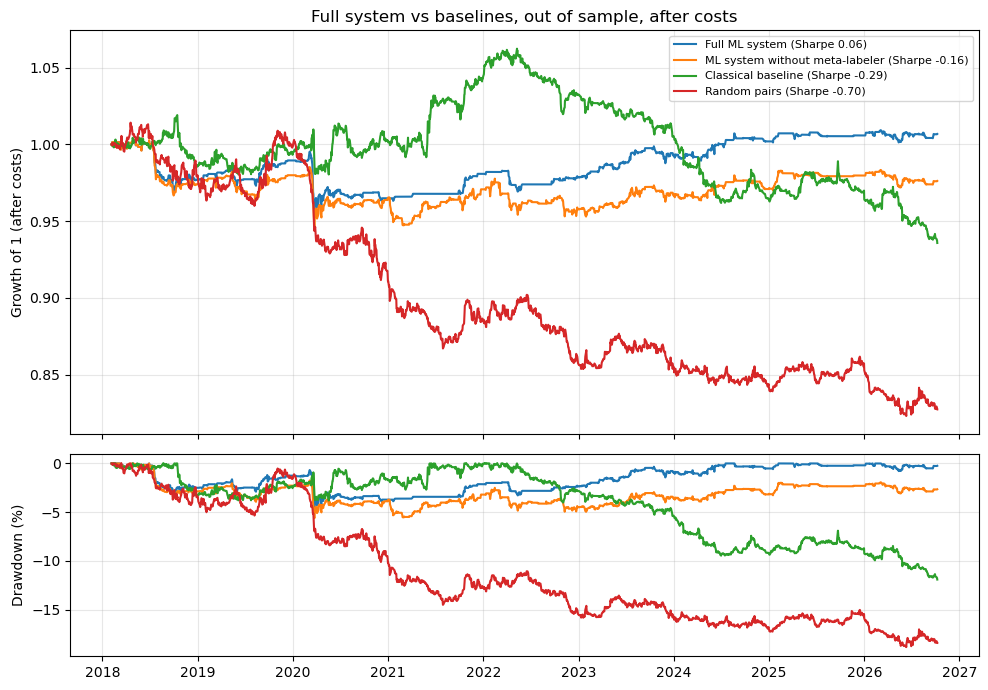

In [47]:
curves = {
    "Full ML system": systems["Full ML system"]["net"],
    "ML system without meta-labeler": ablation_systems["- meta-labeler"]["net"],
    "Classical baseline": systems["Classical baseline (brute force + FDR, static OLS)"]["net"],
    "Random pairs": systems["Random pairs (null), static OLS"]["net"],
}
plot_equity(curves, "Full system vs baselines, out of sample, after costs", "final_tearsheet.png")

## 9.5 Is the Sharpe ratio just luck?

**Block bootstrap.** Re-sample the daily returns in blocks of 20 days (keeping their day-to-day
pattern), 1,000 times, and look at the 95% range of the Sharpe ratio.

**Probabilistic Sharpe ratio (PSR).** The probability that the true Sharpe is above a hurdle
$SR^*$, allowing for skewness $\gamma_3$ and fat tails $\gamma_4$ ($\widehat{SR}$ = daily Sharpe,
$n$ = days):

$$\mathrm{PSR} = \Phi\!\left(\frac{(\widehat{SR} - SR^*)\sqrt{n-1}}{\sqrt{1 - \gamma_3\widehat{SR} + \frac{\gamma_4-1}{4}\widehat{SR}^2}}\right)$$

**Deflated Sharpe ratio (DSR).** We tried many variants (the `TRIALS` list). With $N$ trials, the
best Sharpe that luck alone would give is

$$SR^* = \sigma_{SR}\left[(1-\gamma)\,\Phi^{-1}\!\left(1-\tfrac1N\right) + \gamma\,\Phi^{-1}\!\left(1-\tfrac1{Ne}\right)\right],\quad \gamma \approx 0.5772,$$

and the DSR is the PSR with that hurdle (Bailey and López de Prado).

In [48]:
def block_bootstrap_sharpe(returns, n_samples, block_days, seed):
    """Sharpe ratios of re-sampled return series made of random 20-day blocks."""
    rng = np.random.RandomState(seed)
    values = returns.values
    n = len(values)
    n_blocks = int(np.ceil(n / block_days))
    sharpes = np.zeros(n_samples)
    for k in range(n_samples):
        starts = rng.randint(0, n - block_days + 1, size=n_blocks)
        sample = np.concatenate([values[start:start + block_days] for start in starts])[:n]
        if sample.std(ddof=1) > 0:
            sharpes[k] = sample.mean() / sample.std(ddof=1) * np.sqrt(252)
    return sharpes


def sharpe_probability(returns, hurdle):
    """Probability that the true daily Sharpe is above `hurdle` (PSR; with the luck hurdle = DSR)."""
    values = returns.values
    std = values.std(ddof=1)
    if std == 0:
        return 0.5
    sr = values.mean() / std
    variance_term = 1.0 - skew(values) * sr + (kurtosis(values, fisher=False) - 1.0) / 4.0 * sr * sr
    return float(norm.cdf((sr - hurdle) * np.sqrt(len(values) - 1) / np.sqrt(variance_term)))


def expected_max_sharpe(trial_sharpes):
    """The highest daily Sharpe that luck alone would give after this many trials."""
    n_trials = len(trial_sharpes)
    euler_gamma = 0.5772156649
    first = (1.0 - euler_gamma) * norm.ppf(1.0 - 1.0 / n_trials)
    second = euler_gamma * norm.ppf(1.0 - 1.0 / (n_trials * np.e))
    return float(np.std(trial_sharpes, ddof=1) * (first + second))

In [49]:
trial_sharpes = np.array(list(TRIALS.values()))
hurdle = expected_max_sharpe(trial_sharpes)
rows = []
for label, system in systems.items():
    returns = system["net"]
    boot = block_bootstrap_sharpe(returns, config["bootstrap_samples"], config["bootstrap_block_days"], config["seed"])
    rows.append({
        "strategy": label,
        "sharpe": round(sharpe_ratio(returns), 2),
        "bootstrap_ci_low": round(float(np.percentile(boot, 2.5)), 2),
        "bootstrap_ci_high": round(float(np.percentile(boot, 97.5)), 2),
        "psr_single_test": round(sharpe_probability(returns, 0.0), 3),
        "n_trials": len(trial_sharpes),
        "luck_hurdle_sharpe": round(hurdle * np.sqrt(252), 2),
        "deflated_sharpe": round(sharpe_probability(returns, hurdle), 3),
    })
save_table(pd.DataFrame(rows), "deflated_sharpe")

,strategy,sharpe,bootstrap_ci_low,bootstrap_ci_high,psr_single_test,n_trials,luck_hurdle_sharpe,deflated_sharpe
0,Full ML system,0.06,-0.62,0.77,0.573,50,0.69,0.034
1,"Classical baseline (brute force + FDR, static ...",-0.29,-0.93,0.36,0.196,50,0.69,0.002
2,"Random pairs (null), static OLS",-0.70,-1.32,-0.05,0.020,50,0.69,0.000


> **Result.** The full system's 95% bootstrap range for the Sharpe ratio is −0.62 to 0.77, which
> includes zero. After the 50 variants tried in this notebook, luck alone would be expected to
> produce a Sharpe of about 0.69, far above the system's 0.06, so the deflated Sharpe is only 0.03.
> There is no evidence of real skill.

## 9.6 Error analysis: why did losing trades lose?
Every losing trade gets one cause; the first rule that matches wins:

| Order | Cause | Rule |
|:---:|---|---|
| 1 | cost-dominated | it made money before costs |
| 2 | market shock | NIFTY fell 3%+ in a day, or VIX went above 30, while it was open |
| 3 | company event | one stock moved 8%+ in a single day |
| 4 | relationship break | closed by the stop-loss or the time stop |
| 5 | hedge drift | z went back to 0 but money was lost (the Kalman mean moved to the prices) |
| 6 | other | e.g. closed at the end of the window |

In [50]:
def tag_losing_trade(trade):
    """One cause per losing trade; the first rule that matches wins."""
    if trade["gross_pnl"] >= 0:
        return "cost-dominated"
    if trade["worst_nifty_day"] <= -0.03 or trade["max_vix"] >= 30:
        return "market shock"
    if trade["max_leg_move"] >= 0.08:
        return "company event"
    if trade["reason"] in ("stop", "time"):
        return "relationship break"
    if trade["reason"] == "mean":
        return "hedge drift"
    return "other"


def taken_trades(system):
    """The trades a system actually took, with their size and sized profit."""
    trades = system["result"]["trades"]
    sizes = trades["trade_id"].map(system["weights"]).fillna(0.0)
    taken = trades[sizes > 0].copy()
    taken["size"] = sizes[sizes > 0]
    taken["pnl"] = taken["net_pnl"] * taken["size"]
    return taken

In [51]:
rows = []
for label, system in systems.items():
    taken = taken_trades(system)
    losing = taken[taken["pnl"] < 0].copy()
    losing["tag"] = [tag_losing_trade(trade) for _, trade in losing.iterrows()]
    for tag in ["relationship break", "hedge drift", "market shock", "company event", "cost-dominated", "other"]:
        part = losing[losing["tag"] == tag]
        rows.append({"strategy": label, "tag": tag, "losing_trades": len(part),
                     "share_of_losers_pct": round(100.0 * len(part) / max(len(losing), 1), 1),
                     "total_loss_lakh": round(float(part["pnl"].sum()) / 100000.0, 2)})
save_table(pd.DataFrame(rows), "error_analysis_tags")

# the full system by year and by sector
taken = taken_trades(systems["Full ML system"])
taken["year"] = pd.to_datetime(taken["exit_date"]).dt.year
taken["sector"] = [a if a == b else "cross-sector" for a, b in zip(taken["sector_a"], taken["sector_b"])]

for column, name in [("year", "error_analysis_by_year"), ("sector", "error_analysis_by_sector")]:
    rows = []
    for value in sorted(set(taken[column])):
        part = taken[taken[column] == value]
        rows.append({column: value, "trades": len(part),
                     "hit_rate_pct": round(100.0 * float((part["pnl"] > 0).mean()), 1),
                     "stop_exits": int((part["reason"] == "stop").sum()),
                     "net_pnl_lakh": round(float(part["pnl"].sum()) / 100000.0, 2)})
    save_table(pd.DataFrame(rows), name)

,strategy,tag,losing_trades,share_of_losers_pct,total_loss_lakh
0,Full ML system,relationship break,4,1.8,-4.97
1,Full ML system,hedge drift,125,57.6,-47.19
2,Full ML system,market shock,55,25.3,-34.46
3,Full ML system,company event,10,4.6,-21.03
4,Full ML system,cost-dominated,22,10.1,-0.36
5,Full ML system,other,1,0.5,-0.51
6,"Classical baseline (brute force + FDR, static ...",relationship break,334,75.7,-210.88
7,"Classical baseline (brute force + FDR, static ...",hedge drift,1,0.2,-0.82
8,"Classical baseline (brute force + FDR, static ...",market shock,36,8.2,-27.60
9,"Classical baseline (brute force + FDR, static ...",company event,44,10.0,-49.74


,year,trades,hit_rate_pct,stop_exits,net_pnl_lakh
0,2018,74,56.8,3,-9.22
1,2019,59,66.1,0,5.13
2,2020,148,49.3,14,-9.97
3,2021,18,61.1,1,6.57
4,2022,22,54.5,0,-0.92
5,2023,58,67.2,2,6.44
6,2024,59,54.2,0,3.09
7,2025,19,52.6,0,1.56
8,2026,42,57.1,4,0.38


,sector,trades,hit_rate_pct,stop_exits,net_pnl_lakh
0,Auto,22,50.0,3,-4.77
1,Banks,25,32.0,4,-2.69
2,Chemicals,3,66.7,0,0.47
3,Consumer,8,50.0,0,-1.40
4,Energy,12,83.3,2,2.51
5,FMCG,9,66.7,1,1.56
6,Financials,16,75.0,1,2.23
7,IT,8,87.5,0,1.45
8,Industrials,7,42.9,0,-3.65
9,Metals,13,69.2,1,0.69


> **Result.** 76% of the baseline's losing trades are relationship breaks: the pair simply stopped
> moving together. For the full system, 58% are hedge drift and 25% market shocks. 2020 (the COVID
> crash) was the worst year.

---
# 10. Conclusions

| Research question | Answer |
|---|---|
| **RQ1** Does PCA + clustering beat testing every pair? | **Partly.** k-means needs 88% fewer tests and finds pairs that last longer, but inside the full system testing every pair scored higher. |
| **RQ2** Can a classifier pick the trades that work? | **Weakly.** AUC is only about 0.54, yet the meta-labeler is the most useful single part of the system. |
| **RQ3** Does a Kalman hedge ratio beat a fixed one? | **Yes.** Better Sharpe, about half the drawdown, less trading. |
| **RQ4** Does a TCN forecast reversion better than OU? | **Better than OU, worse than a simple AR(1).** Its cost gate never blocks a trade. |

> **Bottom line.** Machine learning clearly improves on classical pairs trading (Sharpe 0.06 vs
> −0.29, in all 8 sensitivity settings), but not by enough to beat Indian trading costs: the profit
> after costs is about zero and could be luck. An honest negative result is worth more than a Sharpe
> ratio that looks too good to be true.

### Limitations
- **Survivorship bias:** today's list of futures stocks is used for the whole history.
- **Spot prices** stand in for futures prices; the monthly roll is modelled as a cost only.
- **Speed shortcut:** the cointegration test uses a fixed lag of 1.
- **Not built:** the plan's extensions, such as the HMM regime gate, SHAP explanations and the
  pair-break predictor.